## todos

- wtf noise is still not gaussian!!!!!!!

- different lr for noise and drift (ugly)
- make efficient: re-use data from last run
- grid search over initializations: maybe starting with a very low noise could help

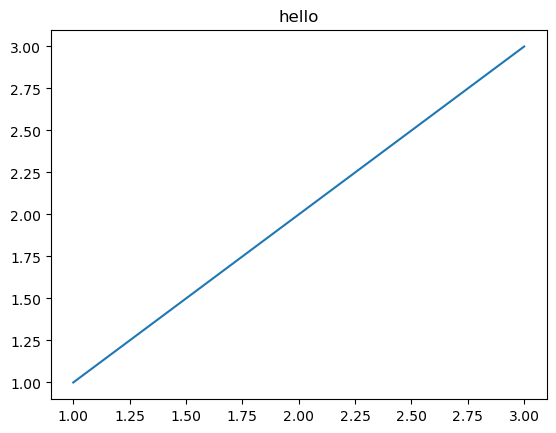

In [1]:
import matplotlib.pyplot as plt
plt.plot([1,2,3],[1,2,3])
plt.title("hello")
plt.show()

## Training CE
- check dataset gen wrt max_steps -> is now so that too slow samples are added to closest
- if possible, make max_steps smaller so loss gets more meaningfull (first check what ce does with zeros (should be irrelevant) and if there is too many "classes")

[[45.  1.]
 [29.  1.]
 [67.  1.]
 ...
 [13.  1.]
 [41.  1.]
 [25.  1.]]
      response    rt
0          1.0  45.0
1          1.0  29.0
2          1.0  67.0
3          1.0  66.0
4         -1.0  36.0
...        ...   ...
9995       1.0  82.0
9996       1.0  67.0
9997       1.0  13.0
9998       1.0  41.0
9999       1.0  25.0

[10000 rows x 2 columns]


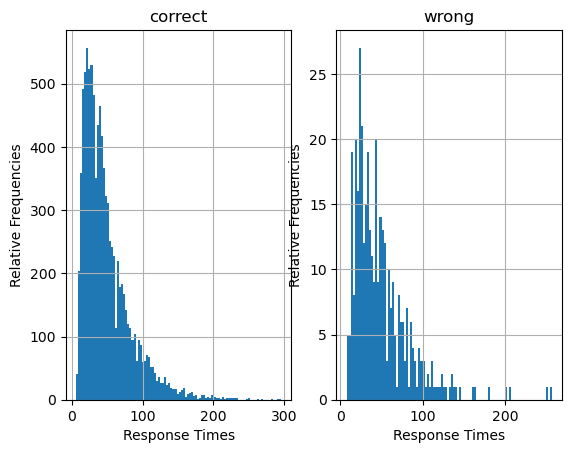

In [7]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt

z0=0.5
sigma=0.2
drift=0.01
max_steps=300
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]


ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

target[:max_steps]=torch.from_numpy(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]/n_data)
target[max_steps:]=torch.from_numpy(np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]/n_data)


 10%|███████▉                                                                         | 39/400 [01:03<09:00,  1.50s/it]

loss: 6.395616054534912
sigma: 0.28870823979377747
drift: 0.1088869720697403


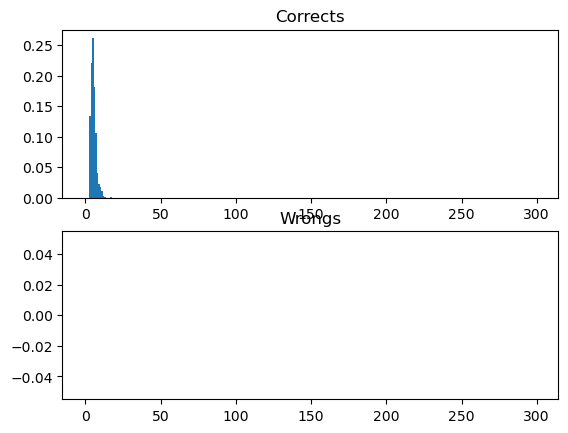

 20%|███████████████▉                                                                 | 79/400 [02:02<07:49,  1.46s/it]

loss: 6.395504474639893
sigma: 0.2780897319316864
drift: 0.10778429359197617


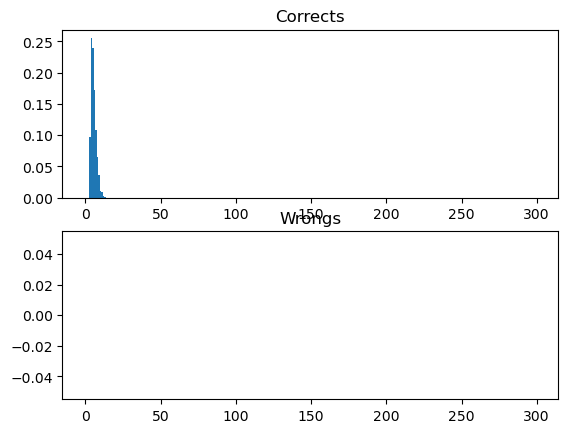

 30%|███████████████████████▊                                                        | 119/400 [03:01<06:41,  1.43s/it]

loss: 6.395656585693359
sigma: 0.2674945890903473
drift: 0.10604304820299149


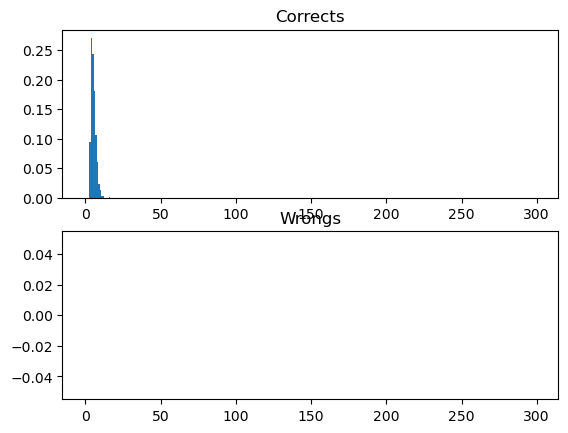

 40%|███████████████████████████████▊                                                | 159/400 [04:02<05:58,  1.49s/it]

loss: 6.395444393157959
sigma: 0.25704556703567505
drift: 0.10434512048959732


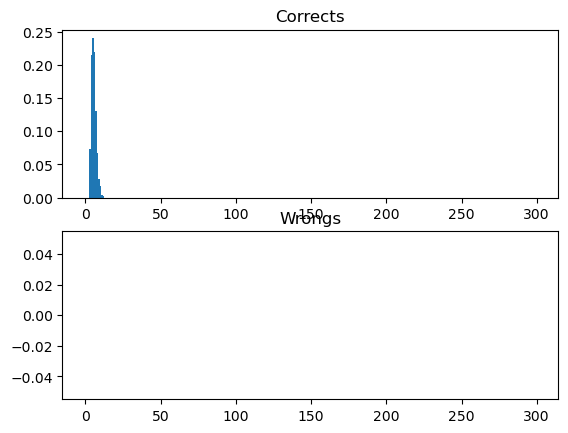

 50%|███████████████████████████████████████▊                                        | 199/400 [05:02<04:55,  1.47s/it]

loss: 6.395406246185303
sigma: 0.2464437037706375
drift: 0.1030493825674057


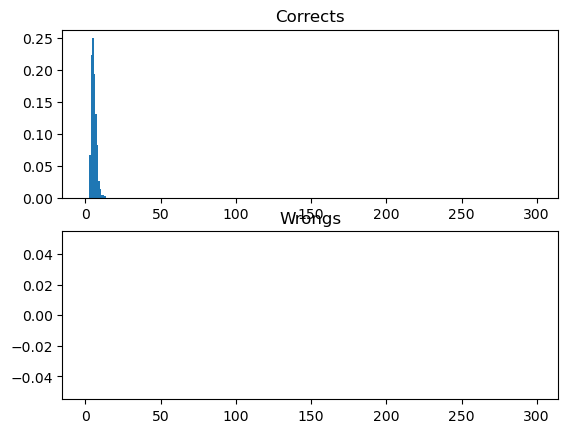

 60%|███████████████████████████████████████████████▊                                | 239/400 [06:02<03:50,  1.43s/it]

loss: 6.395367622375488
sigma: 0.236040860414505
drift: 0.10138726234436035


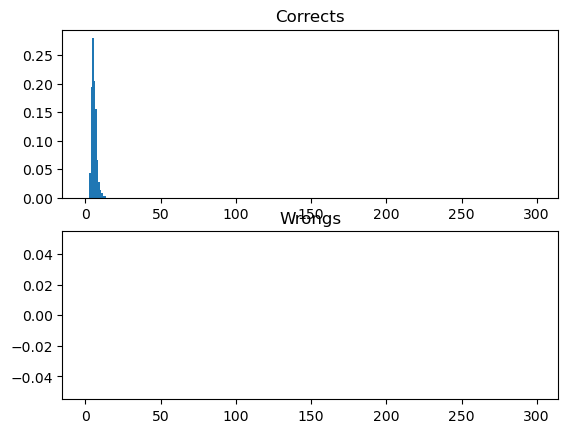

 70%|███████████████████████████████████████████████████████▊                        | 279/400 [07:04<03:03,  1.52s/it]

loss: 6.395398139953613
sigma: 0.22563490271568298
drift: 0.1000187024474144


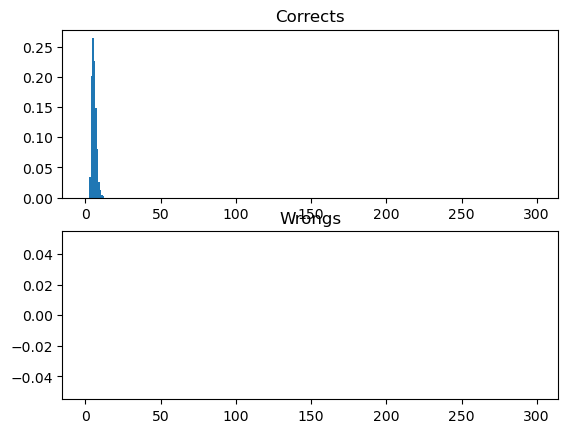

 80%|███████████████████████████████████████████████████████████████▊                | 319/400 [08:06<02:05,  1.55s/it]

loss: 6.395355224609375
sigma: 0.21532437205314636
drift: 0.09873917698860168


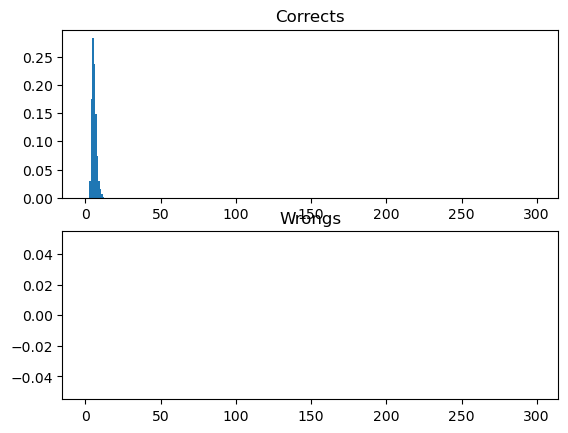

 90%|███████████████████████████████████████████████████████████████████████▊        | 359/400 [09:10<01:04,  1.56s/it]

loss: 6.395306587219238
sigma: 0.20497944951057434
drift: 0.09724195301532745


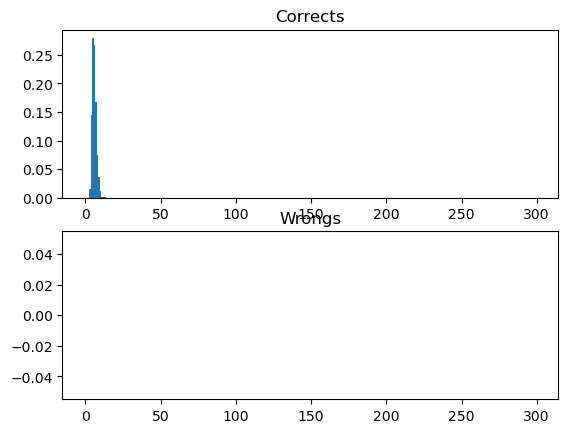

100%|███████████████████████████████████████████████████████████████████████████████▊| 399/400 [10:13<00:01,  1.58s/it]

loss: 6.395312309265137
sigma: 0.19479043781757355
drift: 0.09607923030853271


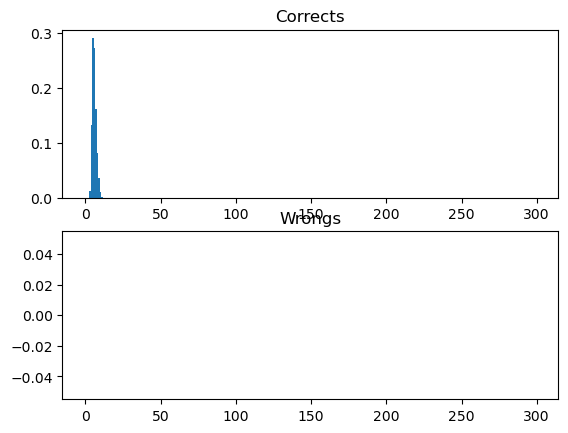

100%|████████████████████████████████████████████████████████████████████████████████| 400/400 [10:16<00:00,  1.54s/it]


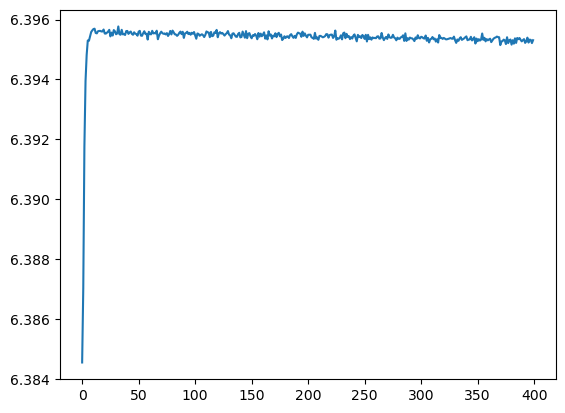

In [8]:
import torch
from tqdm import tqdm

epochs=400#10000000#-00
lr=0.1
annealing=False

n_data=10000
initial_drift=0.02
initial_sigma=0.3

sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.CrossEntropyLoss()
losses=[]
optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()

    for _ in range(sample_size):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recicle without getting problems for the graph
        if z>0.5:
            y[0,t]+=(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t]+=((z-(z.detach())-1)*-1)[0]
    
    y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        print(f"sigma: {model.layer.weight.data[0,0]}")
        print(f"drift: {model.layer.bias.data[0]}")
        
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.5
            
plt.plot(range(len(losses)), losses)
plt.show()

In [23]:
print(model.layer.weight.data)
print(model.layer.bias.data)

tensor([[0.3000]])
tensor([0.0205])


In [8]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.4684]], requires_grad=True),
 Parameter containing:
 tensor([0.1934], requires_grad=True)]

In [37]:
z=torch.tensor([-0.0757])
z=(z-(z.detach())-1)*-1
print(z)
y[1,1]+=z[0]

tensor([1.])


## CE cumsum
- still look above

!see if mean trick would be better

[[140.  -1.]
 [ 12.   1.]
 [ 27.  -1.]
 ...
 [ 40.   1.]
 [ 33.  -1.]
 [ 51.   1.]]
wrongs: 4069
      response     rt
0         -1.0  140.0
1          1.0   12.0
2         -1.0   27.0
3         -1.0   86.0
4          1.0   14.0
...        ...    ...
9995       1.0   36.0
9996      -1.0   39.0
9997       1.0   40.0
9998      -1.0   33.0
9999       1.0   51.0

[10000 rows x 2 columns]


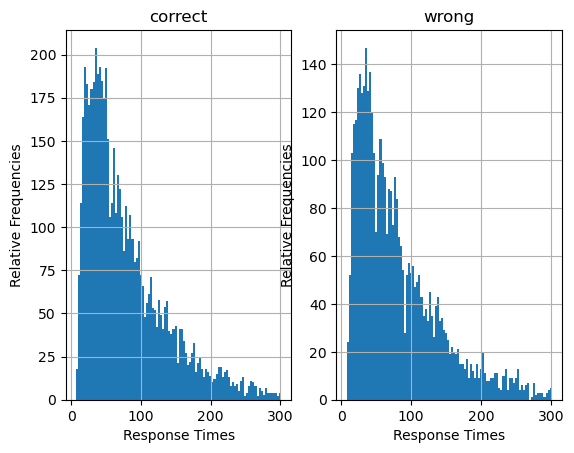

2180127


In [8]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt

z0=0.5
sigma=0.2
drift=0.001
max_steps=300
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]

print("wrongs:",(df["response"]==-1).sum())

ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

'''for i in range(max_steps):
    corrects[i]=corrects[:i+1].sum()
    wrongs[i]=wrongs[:i+1].sum()'''

corrects=np.cumsum(corrects)
wrongs=np.cumsum(wrongs)

cum=np.sum(corrects+wrongs)

print(cum)
target[:max_steps]=torch.from_numpy(corrects/cum)
target[max_steps:]=torch.from_numpy(wrongs/cum)


 10%|███████▉                                                                         | 39/400 [00:18<01:51,  3.23it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


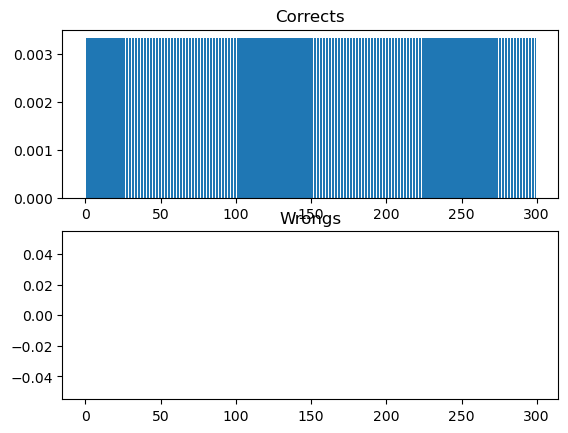

 20%|███████████████▉                                                                 | 79/400 [00:33<01:39,  3.21it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


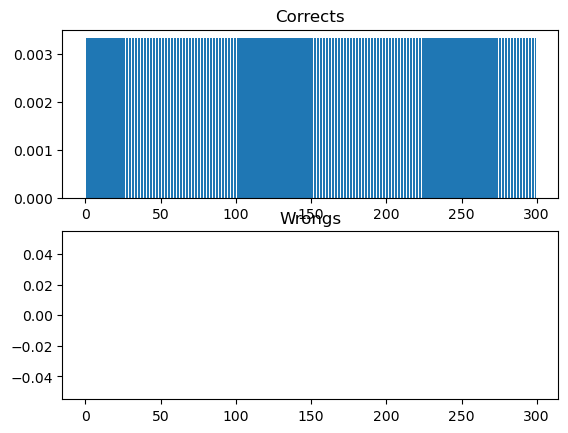

 30%|███████████████████████▊                                                        | 119/400 [00:46<01:25,  3.27it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


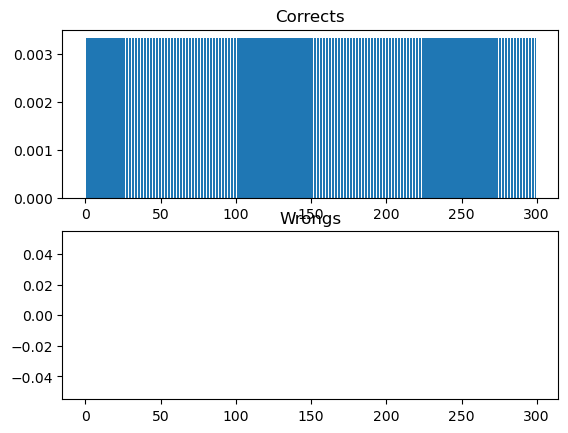

 40%|███████████████████████████████▊                                                | 159/400 [01:01<01:15,  3.18it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


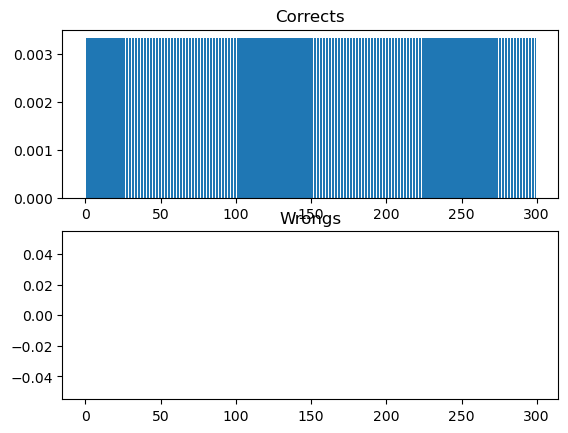

 50%|███████████████████████████████████████▊                                        | 199/400 [01:14<01:03,  3.17it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


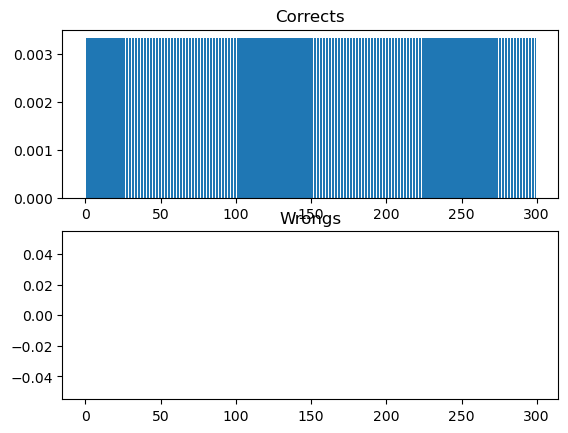

 60%|███████████████████████████████████████████████▊                                | 239/400 [01:29<00:56,  2.86it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


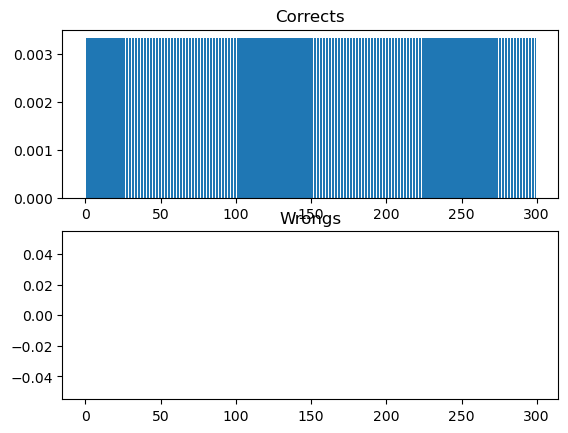

 70%|███████████████████████████████████████████████████████▊                        | 279/400 [01:44<00:39,  3.08it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


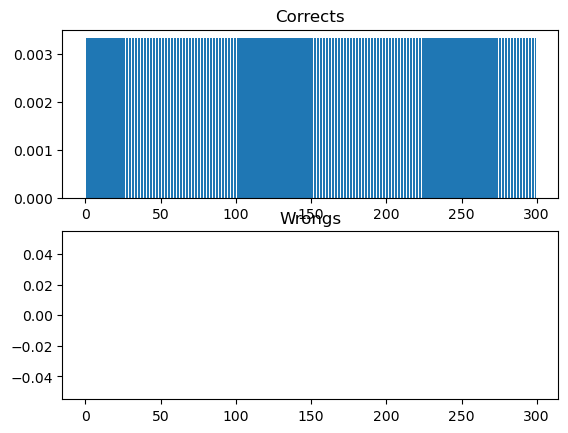

 80%|███████████████████████████████████████████████████████████████▊                | 319/400 [01:58<00:25,  3.21it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


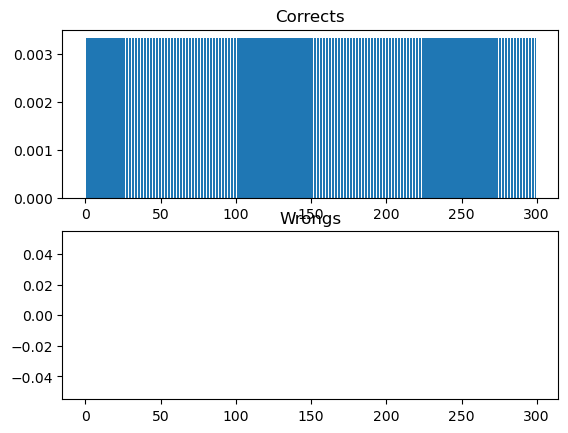

 90%|███████████████████████████████████████████████████████████████████████▊        | 359/400 [02:12<00:12,  3.22it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


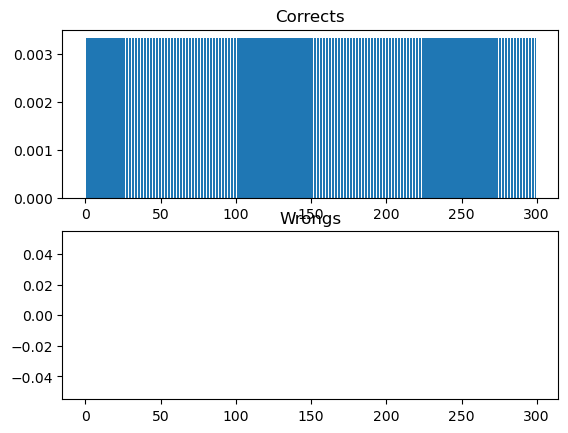

100%|███████████████████████████████████████████████████████████████████████████████▊| 399/400 [02:26<00:00,  3.22it/s]

loss: 6.396627902984619
sigma: 0.30000054836273193
drift: 2.3677480220794678


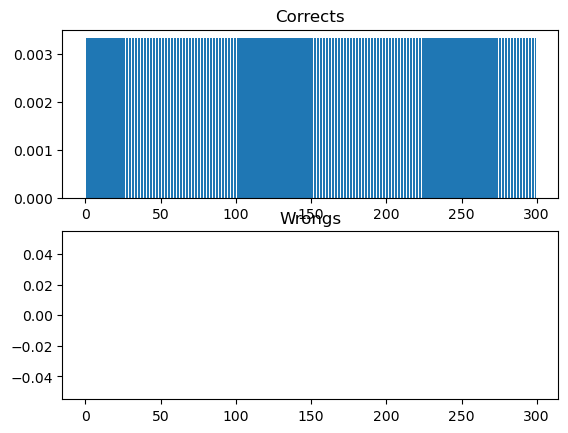

100%|████████████████████████████████████████████████████████████████████████████████| 400/400 [02:28<00:00,  2.69it/s]


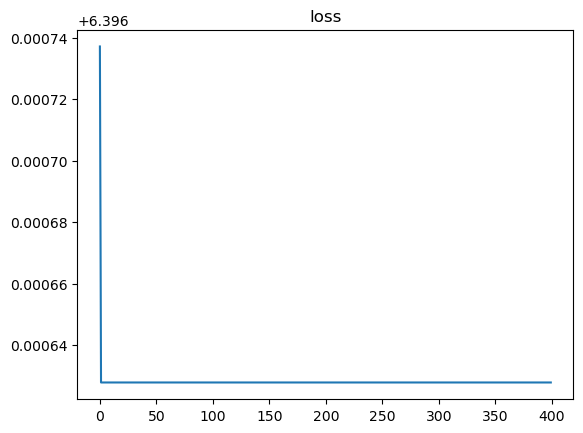

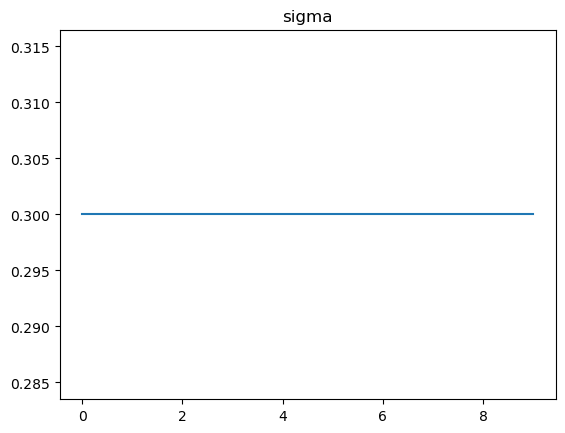

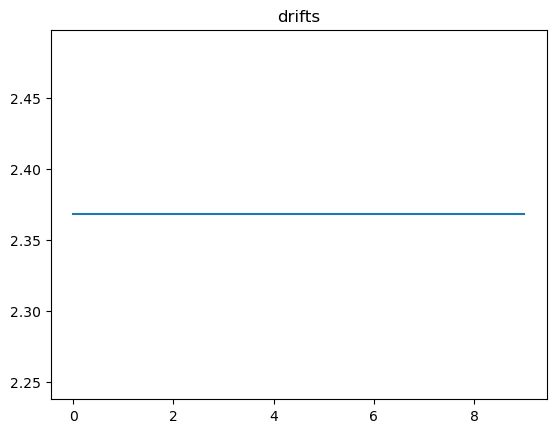

In [9]:
import torch
from tqdm import tqdm

epochs=400#10000000#-00
lr=100.0
annealing=True

n_data=10000
initial_drift=0.0
initial_sigma=0.3

sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()

    for _ in range(sample_size):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recicle without getting problems for the graph
        if z>0.5:
            y[0,t]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
    
    y=torch.cumsum(y, 1)
    
    #should I detach?
    y=y/torch.sum(y)
    

    #y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        sigmas.append(model.layer.weight.data[0,0].detach())
        drifts.append(model.layer.bias.data[0].detach())
        
        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")
        
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7
            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

In [23]:
print(model.layer.weight.data)
print(model.layer.bias.data)

tensor([[0.3000]])
tensor([0.0205])


In [8]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.4684]], requires_grad=True),
 Parameter containing:
 tensor([0.1934], requires_grad=True)]

In [37]:
z=torch.tensor([-0.0757])
z=(z-(z.detach())-1)*-1
print(z)
y[1,1]+=z[0]

tensor([1.])


## MSE no cumsum
- still look above

seems to be bigger than ce
- maybe it shoud be cumsum, so that ts get more puled towards being late (otherwise being late is part of the loss but not taken into account for differention
- try not normalizing

[[139.  -1.]
 [ 14.   1.]
 [ 20.   1.]
 ...
 [168.  -1.]
 [ 52.   1.]
 [ 22.   1.]]
wrongs: 4157
      response     rt
0         -1.0  139.0
1          1.0   14.0
2          1.0   20.0
3         -1.0  155.0
4          1.0   50.0
...        ...    ...
9995      -1.0   20.0
9996      -1.0   69.0
9997      -1.0  168.0
9998       1.0   52.0
9999       1.0   22.0

[10000 rows x 2 columns]


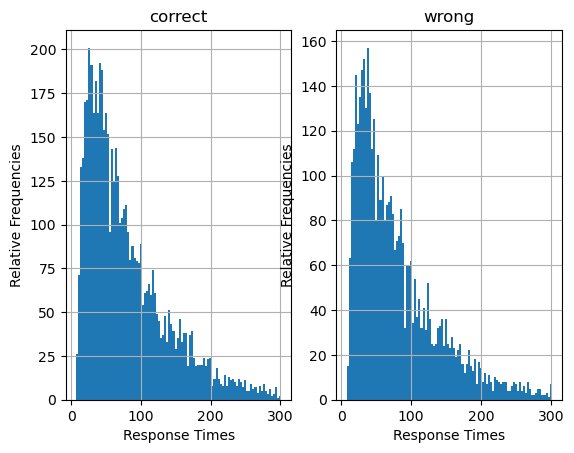

9865


In [19]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt

z0=0.5
sigma=0.2
drift=0.001
max_steps=300
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]

print("wrongs:",(df["response"]==-1).sum())

ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

'''for i in range(max_steps):
    corrects[i]=corrects[:i+1].sum()
    wrongs[i]=wrongs[:i+1].sum()'''

#corrects=np.cumsum(corrects)
#wrongs=np.cumsum(wrongs)



corrects=gaussian_filter1d(corrects, 6, mode="constant")
wrongs=gaussian_filter1d(wrongs, 6, mode="constant")
cum=np.sum(corrects+wrongs)

corrects_old=corrects
wrongs_old=wrongs
cum_old=cum

print(cum)
target[:max_steps]=torch.from_numpy(corrects/cum)
target[max_steps:]=torch.from_numpy(wrongs/cum)


In [22]:
loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
a=torch.Tensor([1,0,0,0,0])
b=torch.Tensor([0,1,0,0,0])
print(loss_function(a,b))

b=torch.Tensor([0.1,0.9,0,0,0])
print(loss_function(a,b))

tensor(0.4000)
tensor(0.3240)


original drift: 0.001, sigma: 0.2


 10%|███████▉                                                                         | 39/400 [04:04<36:07,  6.01s/it]

loss: 5.731471446779324e-06
sigma: 0.2999996840953827
drift: 0.0005132992519065738


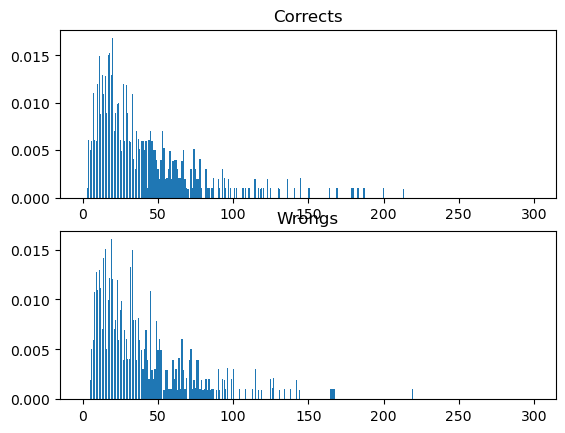

 20%|███████████████▉                                                                 | 79/400 [08:04<31:57,  5.97s/it]

loss: 6.5536883084860165e-06
sigma: 0.29999855160713196
drift: 0.0008860621601343155


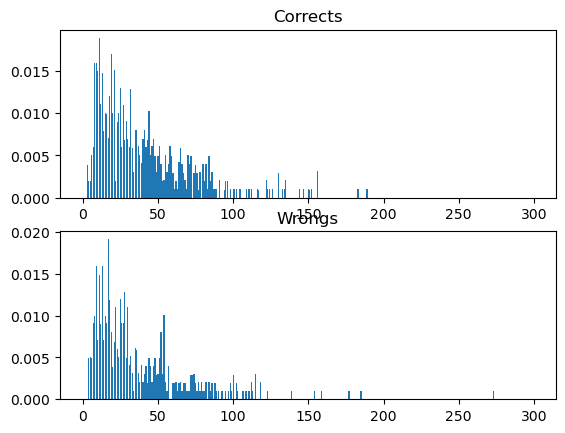

 30%|███████████████████████▊                                                        | 119/400 [12:11<28:56,  6.18s/it]

loss: 5.611176220554626e-06
sigma: 0.29999762773513794
drift: 0.0011056531220674515


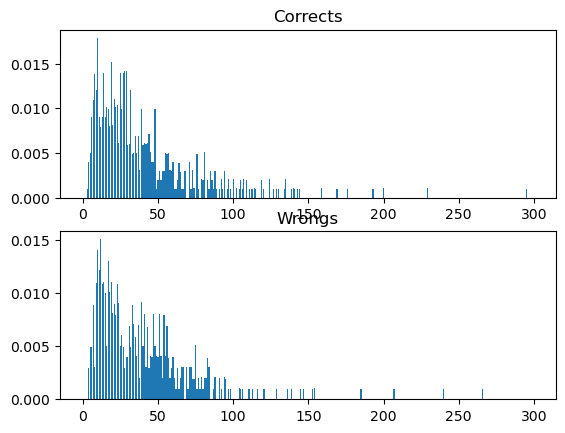

 40%|███████████████████████████████▊                                                | 159/400 [16:14<24:37,  6.13s/it]

loss: 6.428808774217032e-06
sigma: 0.2999972999095917
drift: 0.0012331078760325909


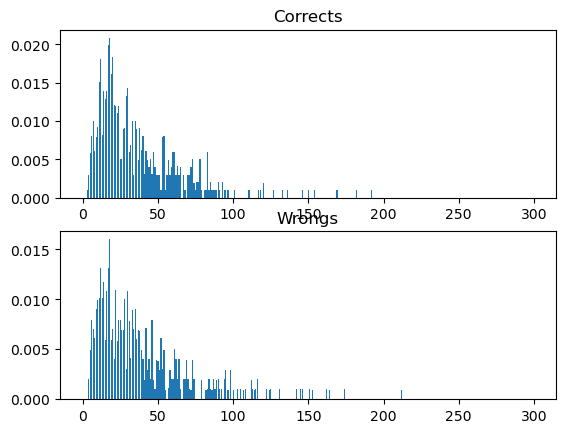

 50%|███████████████████████████████████████▊                                        | 199/400 [20:17<21:16,  6.35s/it]

loss: 6.091244358685799e-06
sigma: 0.2999972701072693
drift: 0.0013148245634511113


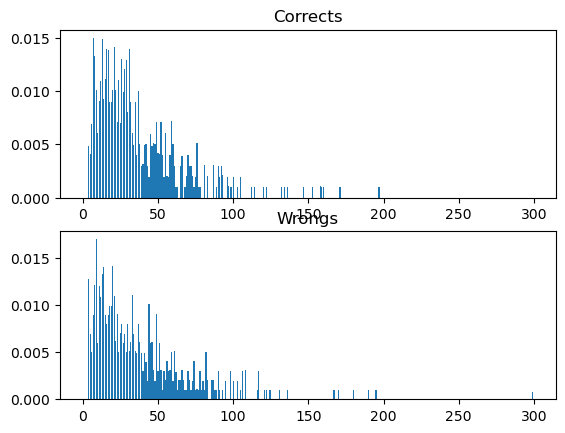

 60%|███████████████████████████████████████████████▊                                | 239/400 [24:22<16:01,  5.97s/it]

loss: 5.579200660577044e-06
sigma: 0.2999972701072693
drift: 0.0013695923844352365


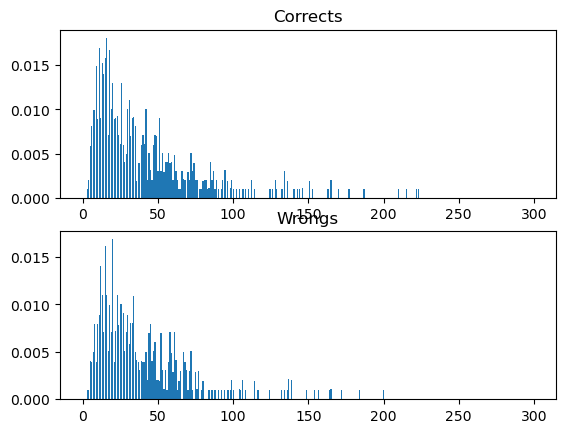

 70%|███████████████████████████████████████████████████████▊                        | 279/400 [28:30<12:36,  6.25s/it]

loss: 6.587432380911196e-06
sigma: 0.2999972701072693
drift: 0.001413801801390946


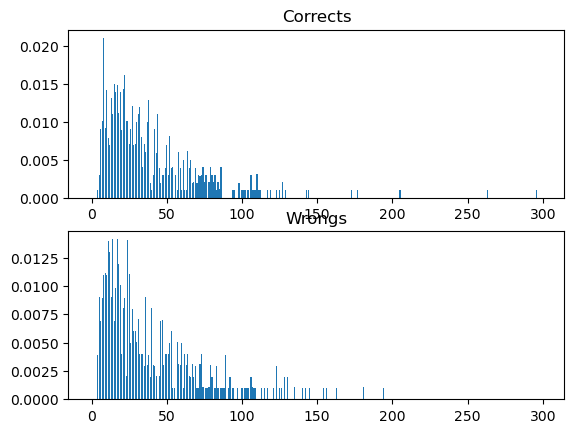

 80%|███████████████████████████████████████████████████████████████▊                | 319/400 [32:32<08:13,  6.10s/it]

loss: 5.87810245633591e-06
sigma: 0.2999972701072693
drift: 0.0014377449406310916


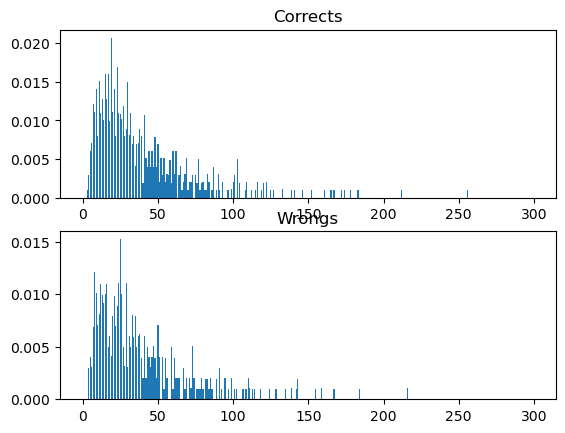

 90%|███████████████████████████████████████████████████████████████████████▊        | 359/400 [36:37<04:07,  6.03s/it]

loss: 6.539706646435661e-06
sigma: 0.2999972701072693
drift: 0.0014578717527911067


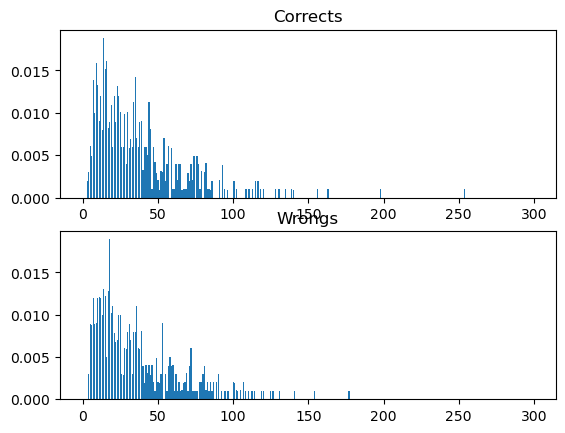

100%|███████████████████████████████████████████████████████████████████████████████▊| 399/400 [40:38<00:06,  6.07s/it]

loss: 5.550868081627414e-06
sigma: 0.2999972701072693
drift: 0.0014701149193570018


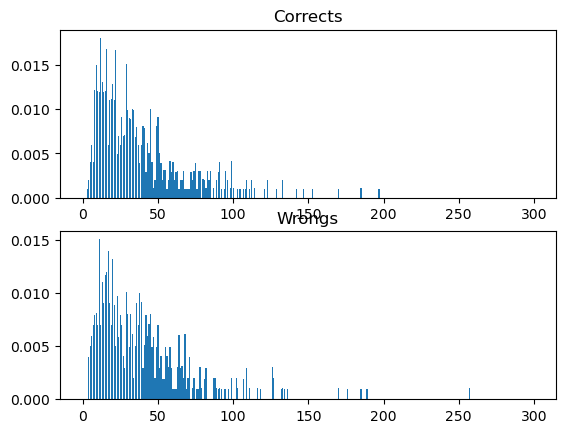

100%|████████████████████████████████████████████████████████████████████████████████| 400/400 [40:45<00:00,  6.11s/it]


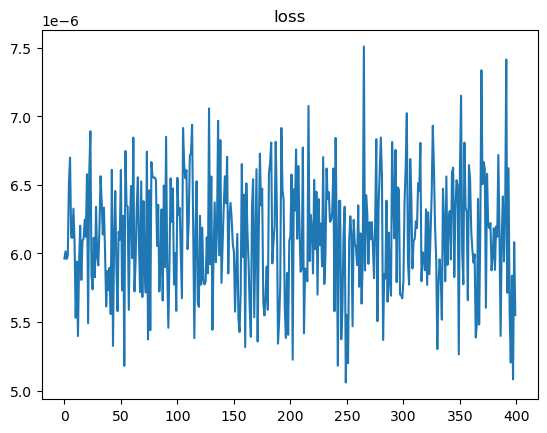

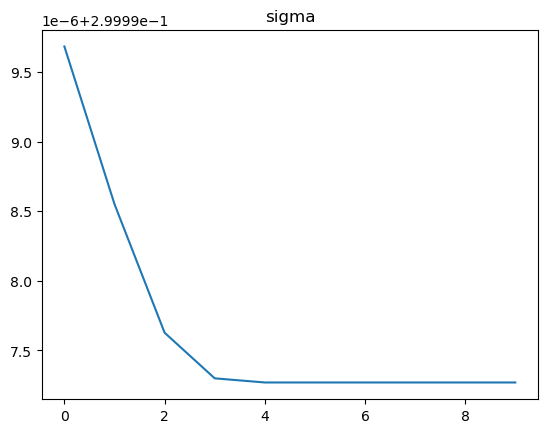

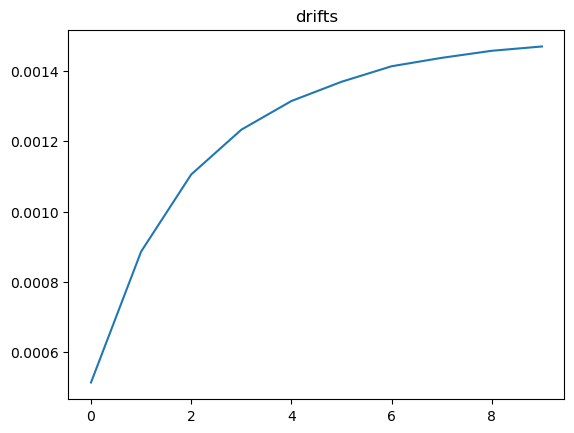

In [27]:
import torch
from tqdm import tqdm

epochs=400#10000000#-00
lr=0.1#100.0
annealing=True

n_data=10000
initial_drift=0.0
initial_sigma=0.3

print(f"original drift: {drift}, sigma: {sigma}")
sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()

    for _ in range(sample_size):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recicle without getting problems for the graph
        if z>0.5:
            y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
    
    #y=torch.cumsum(y, 1)
    
    #should I detach?
    y=y/torch.sum(y)
    

    #y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())
        
        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")
        
        
        cum=sample_size

        fig, axs = plt.subplots(2)
        axs[0].bar(range(max_steps), y[0]/cum, alpha=0.5, label="model")
        axs[1].bar(range(max_steps), y[1]/cum, alpha=0.5, label="model")

        axs[0].bar(range(max_steps), corrects_old/cum_old, alpha=0.5, label="original")
        axs[1].bar(range(max_steps), wrongs_old/cum_old, alpha=0.5, label="original")
        plt.legend()
        plt.show()

        '''
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7
            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

original drift: 0.001, sigma: 0.2


 10%|███████▋                                                                     | 399/4000 [57:13<8:40:30,  8.67s/it]

loss: 6.643094366154401e-06
sigma: 0.2999665439128876
drift: 0.004432711284607649


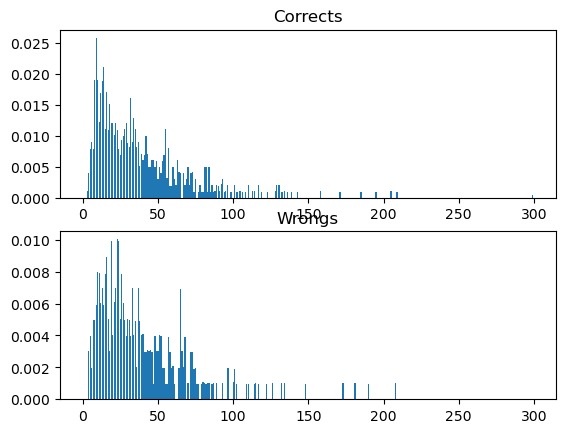

 20%|██████████████▉                                                            | 799/4000 [1:36:28<2:56:23,  3.31s/it]

loss: 7.219097824417986e-06
sigma: 0.29994744062423706
drift: 0.005276816431432962


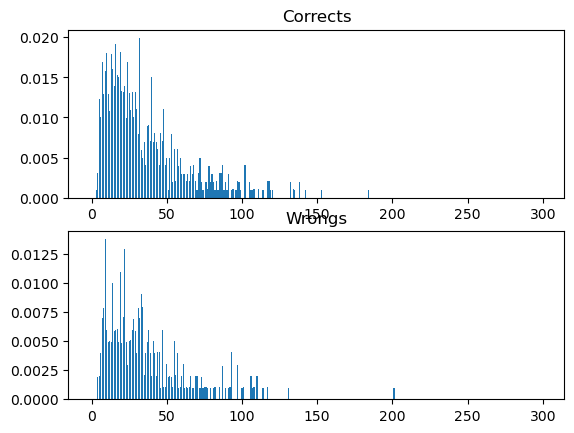

 30%|██████████████████████▏                                                   | 1199/4000 [1:58:00<1:19:21,  1.70s/it]

loss: 7.702514267293736e-06
sigma: 0.2999301850795746
drift: 0.005792326293885708


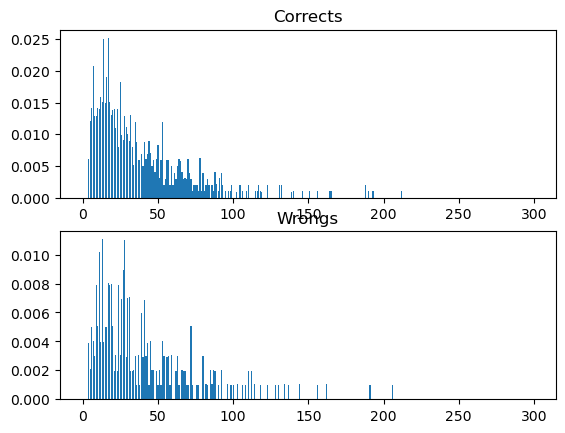

 40%|█████████████████████████████▌                                            | 1599/4000 [2:43:32<1:49:34,  2.74s/it]

loss: 9.934413537848741e-05
sigma: 0.29561707377433777
drift: 0.051444362848997116


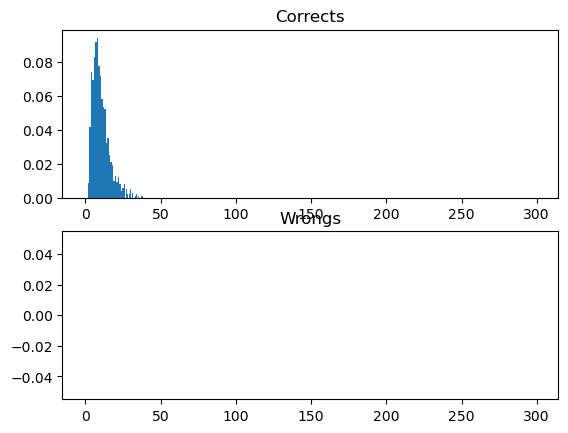

 50%|█████████████████████████████████████▉                                      | 1999/4000 [2:54:01<38:40,  1.16s/it]

loss: 0.0005018240190111101
sigma: 0.26142221689224243
drift: 0.14793890714645386


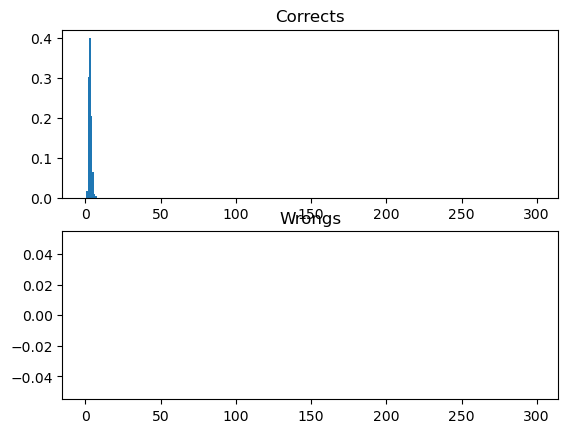

 60%|█████████████████████████████████████████████▌                              | 2399/4000 [3:00:48<26:19,  1.01it/s]

loss: 0.0008169403299689293
sigma: 0.22659285366535187
drift: 0.1961209774017334


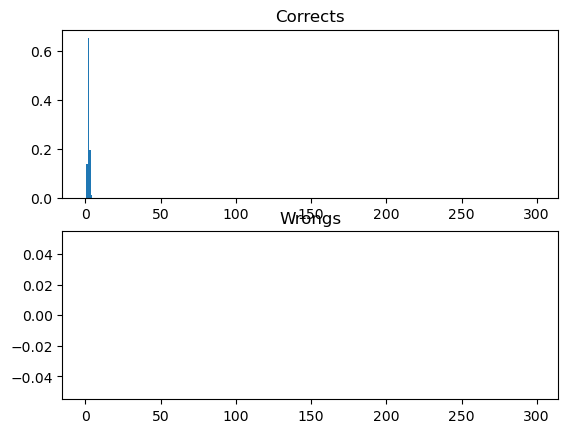

 70%|█████████████████████████████████████████████████████▏                      | 2799/4000 [3:07:00<17:39,  1.13it/s]

loss: 0.0008608546922914684
sigma: 0.21240216493606567
drift: 0.20553335547447205


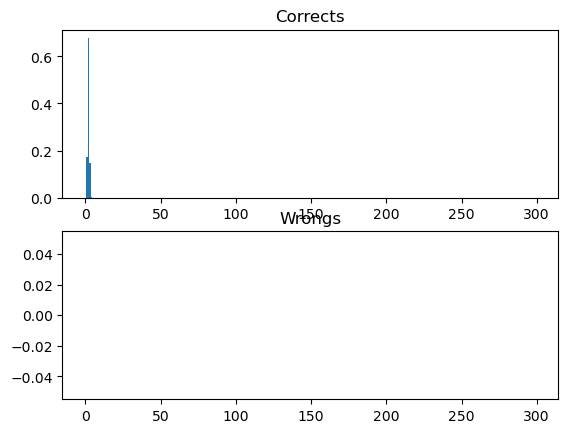

 80%|████████████████████████████████████████████████████████████▊               | 3199/4000 [3:13:07<12:25,  1.07it/s]

loss: 0.0009222099324688315
sigma: 0.20511357486248016
drift: 0.20554447174072266


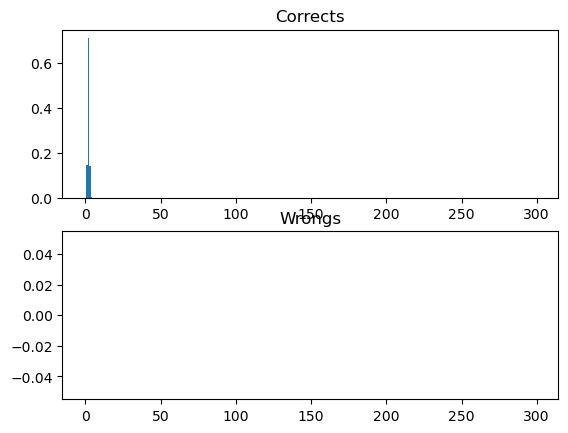

 90%|████████████████████████████████████████████████████████████████████▍       | 3599/4000 [3:19:22<06:13,  1.07it/s]

loss: 0.0009587949607521296
sigma: 0.19781823456287384
drift: 0.20521046221256256


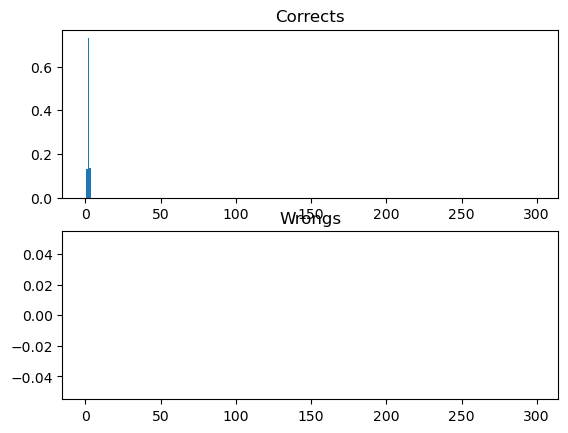

100%|███████████████████████████████████████████████████████████████████████████▉| 3999/4000 [3:25:36<00:00,  1.11it/s]

loss: 0.0009983957279473543
sigma: 0.19046618044376373
drift: 0.20491501688957214


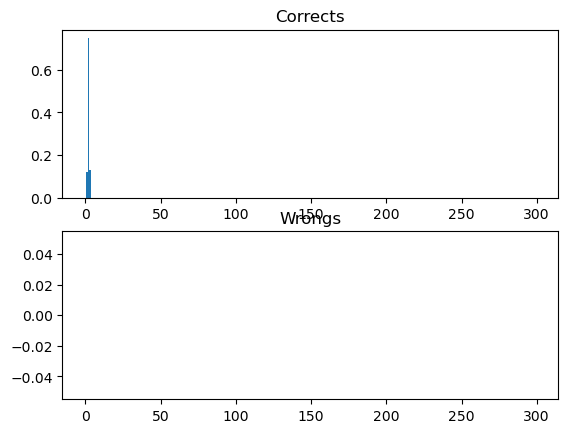

100%|████████████████████████████████████████████████████████████████████████████| 4000/4000 [3:25:39<00:00,  3.08s/it]


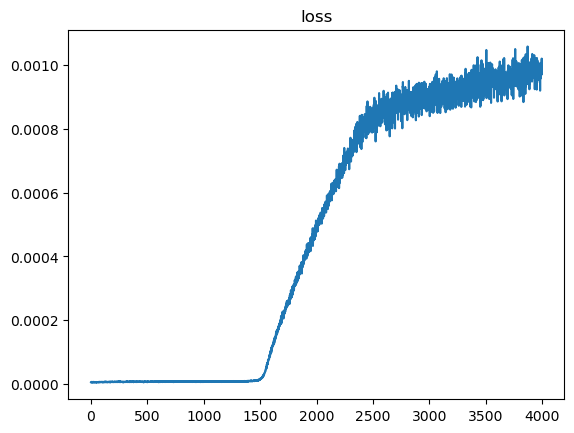

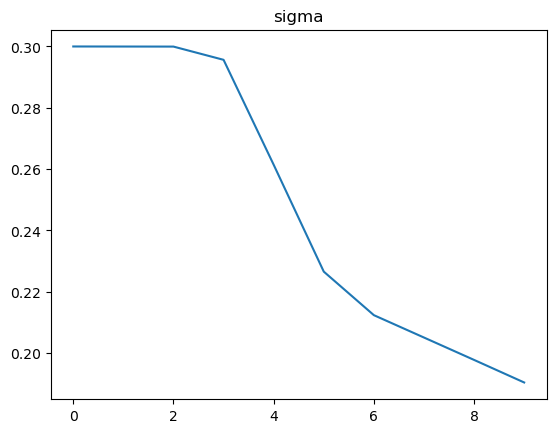

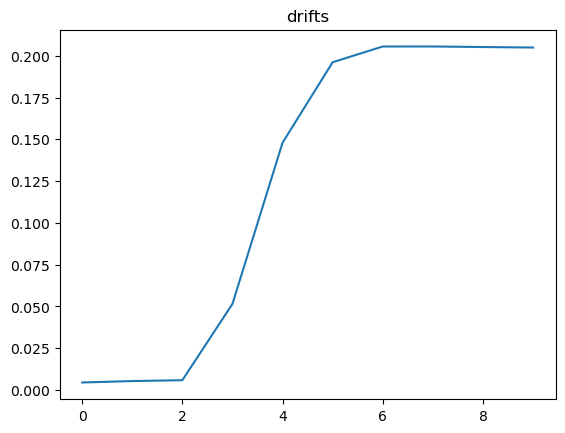

In [29]:
import torch
from tqdm import tqdm

epochs=4000#10000000#-00
lr=0.5#100.0
annealing=False

n_data=10000
initial_drift=-0.001
initial_sigma=0.3

print(f"original drift: {drift}, sigma: {sigma}")
sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()

    for _ in range(sample_size):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recicle without getting problems for the graph
        if z>0.5:
            y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
    
    #y=torch.cumsum(y, 1)
    
    #should I detach?
    y=y/torch.sum(y)
    

    #y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())
        
        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")
        
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7
            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

In [30]:
interesting=model

In [56]:
torch.save(model.state_dict(), "noise_converging_close.pt")

In [ ]:
torch.save({
            'epoch': epoch,
            'model_state_dict': interesting.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),shit I forgot the optimizer
            'loss': loss,
            ...
            }, PATH)

In [26]:
y.size()

torch.Size([2, 300])

In [8]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.4684]], requires_grad=True),
 Parameter containing:
 tensor([0.1934], requires_grad=True)]

In [37]:
z=torch.tensor([-0.0757])
z=(z-(z.detach())-1)*-1
print(z)
y[1,1]+=z[0]

tensor([1.])


## MSE no cumsum (copy for efficiency/sample reusage)

[[ 50.  -1.]
 [ 74.  -1.]
 [ 25.  -1.]
 ...
 [ 73.   1.]
 [150.   1.]
 [ 73.   1.]]
wrongs: 4062
      response     rt
0         -1.0   50.0
1         -1.0   74.0
2         -1.0   25.0
3         -1.0  110.0
4          1.0   41.0
...        ...    ...
9995      -1.0   15.0
9996      -1.0  224.0
9997       1.0   73.0
9998       1.0  150.0
9999       1.0   73.0

[10000 rows x 2 columns]


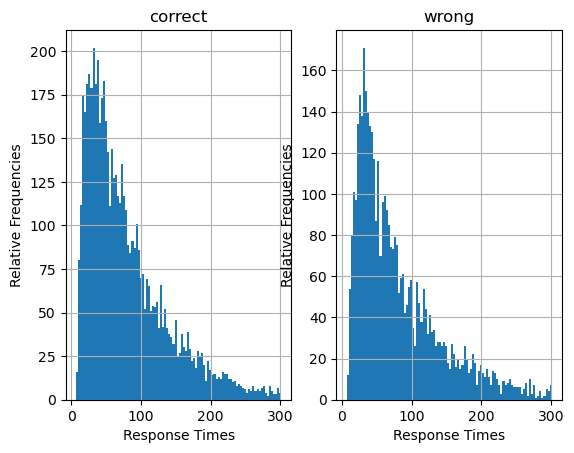

9521


In [31]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt

z0=0.5
sigma=0.2
drift=0.001
max_steps=300
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]

print("wrongs:",(df["response"]==-1).sum())

ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

'''for i in range(max_steps):
    corrects[i]=corrects[:i+1].sum()
    wrongs[i]=wrongs[:i+1].sum()'''

#corrects=np.cumsum(corrects)
#wrongs=np.cumsum(wrongs)



corrects=gaussian_filter1d(corrects, 6, mode="constant")
wrongs=gaussian_filter1d(wrongs, 6, mode="constant")

cum=np.sum(corrects+wrongs)

corrects_old=corrects/cum
wrongs_old=wrongs/cum
cum_old=cum/cum

print(cum)
target[:max_steps]=torch.from_numpy(corrects/cum)
target[max_steps:]=torch.from_numpy(wrongs/cum)


In [52]:
corrects_old=corrects/cum
wrongs_old=wrongs/cum
cum_old=cum/cum

In [51]:
cum=np.sum([corrects, wrongs])
print(np.sum([corrects_old, wrongs_old]))

9.521


In [49]:
print(np.sum([corrects, wrongs]))
print(cum)

9521
9521


original drift: 0.001, sigma: 0.2
init drift: -0.01, sigma: 0.001


 10%|███████▊                                                                       | 199/2000 [03:52<38:52,  1.30s/it]

loss: 0.001001166645437479
sigma: 0.0010000000474974513
drift: -0.009999999776482582


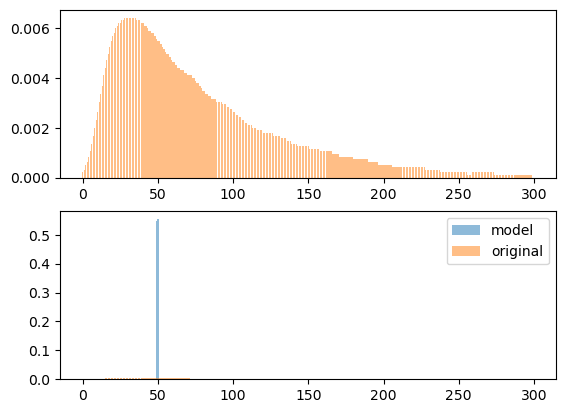

 20%|███████████████▊                                                               | 399/2000 [07:16<06:47,  3.93it/s]

loss: 0.0010020401095971465
sigma: 0.0010000000474974513
drift: -0.009999999776482582


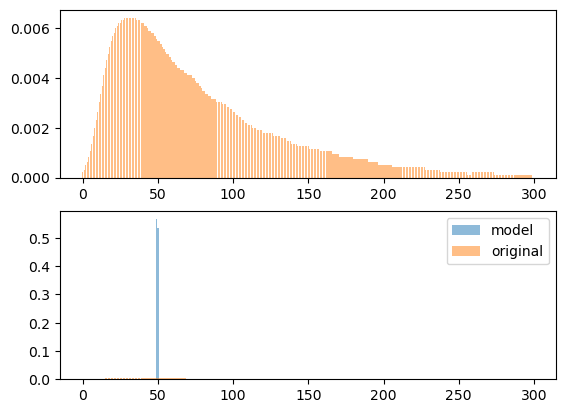

 30%|███████████████████████▋                                                       | 599/2000 [10:26<21:25,  1.09it/s]

loss: 0.0010020858608186245
sigma: 0.0010000000474974513
drift: -0.009999999776482582


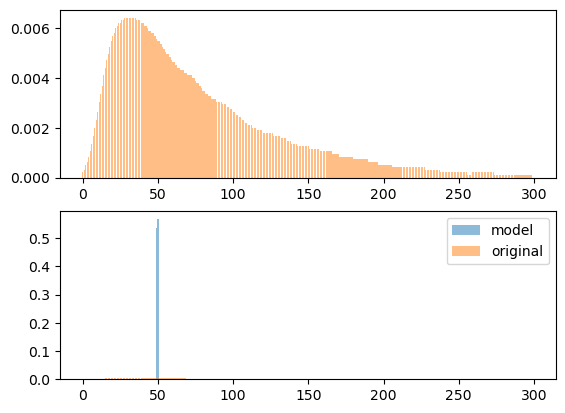

 40%|███████████████████████████████▌                                               | 799/2000 [13:48<19:17,  1.04it/s]

loss: 0.0010011980775743723
sigma: 0.0010000000474974513
drift: -0.009999999776482582


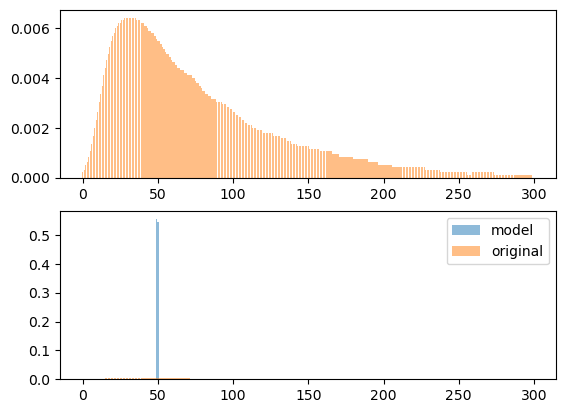

 50%|███████████████████████████████████████▍                                       | 999/2000 [17:09<16:23,  1.02it/s]

loss: 0.0010015374282374978
sigma: 0.0010000000474974513
drift: -0.009999999776482582


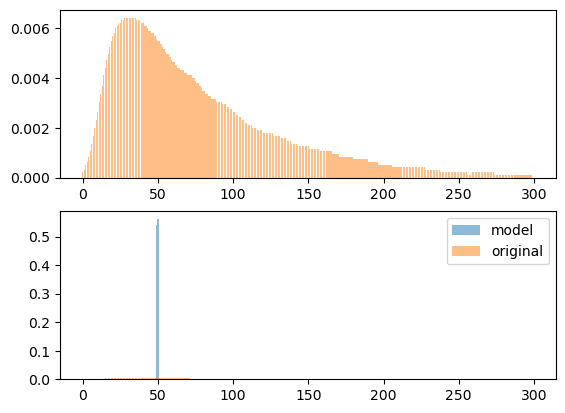

 60%|██████████████████████████████████████████████▊                               | 1199/2000 [20:33<13:48,  1.03s/it]

loss: 0.0010041908826678991
sigma: 0.0010000000474974513
drift: -0.009999999776482582


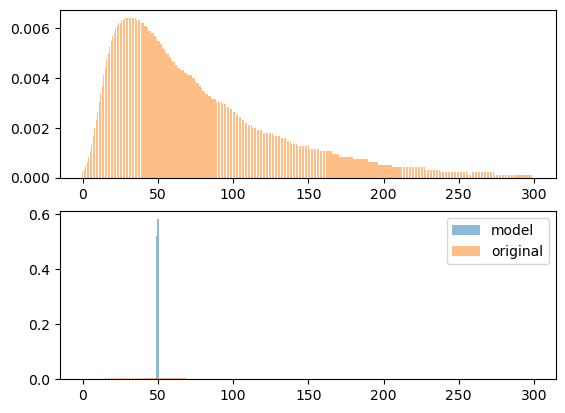

 70%|██████████████████████████████████████████████████████▌                       | 1399/2000 [23:54<11:03,  1.10s/it]

loss: 0.0010013177525252104
sigma: 0.0010000000474974513
drift: -0.009999999776482582


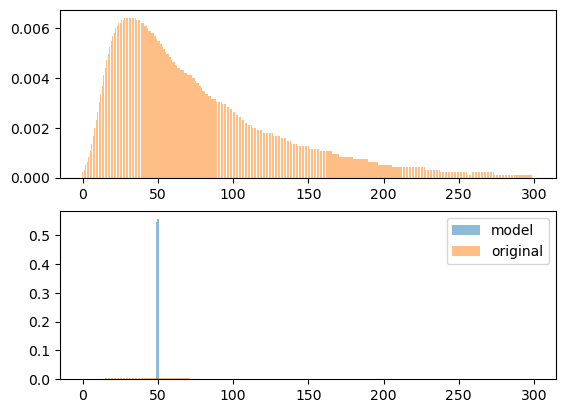

 80%|██████████████████████████████████████████████████████████████▎               | 1599/2000 [27:11<06:51,  1.03s/it]

loss: 0.0010016652522608638
sigma: 0.0010000000474974513
drift: -0.009999999776482582


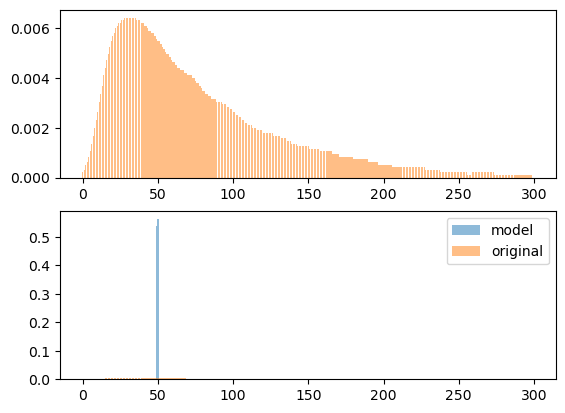

 90%|██████████████████████████████████████████████████████████████████████▏       | 1799/2000 [30:30<03:09,  1.06it/s]

loss: 0.0010032678255811334
sigma: 0.0010000000474974513
drift: -0.009999999776482582


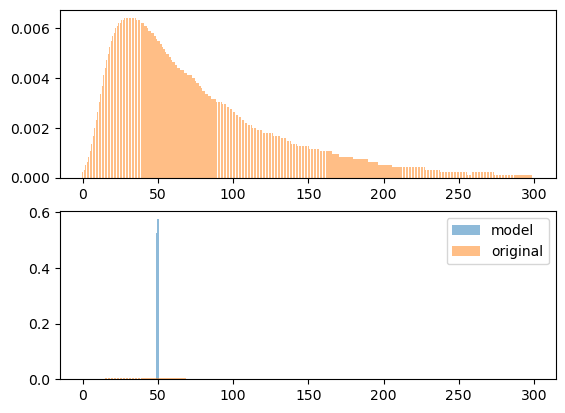

100%|█████████████████████████████████████████████████████████████████████████████▉| 1999/2000 [33:52<00:00,  1.10it/s]

loss: 0.0010023524519056082
sigma: 0.0010000000474974513
drift: -0.009999999776482582


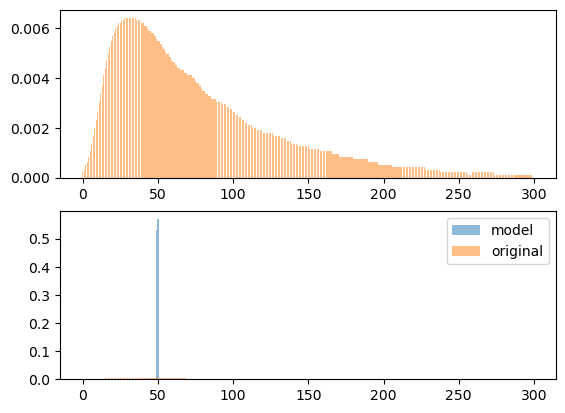

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [33:56<00:00,  1.02s/it]


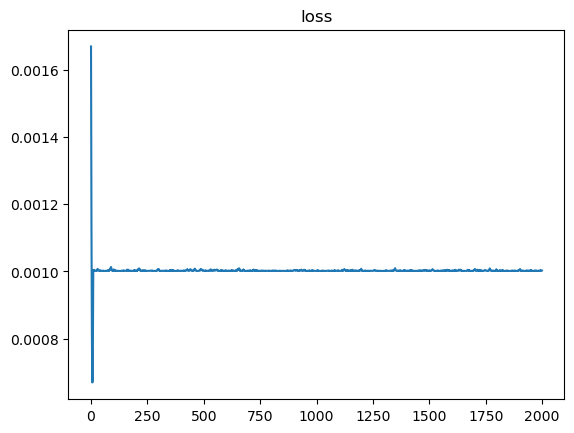

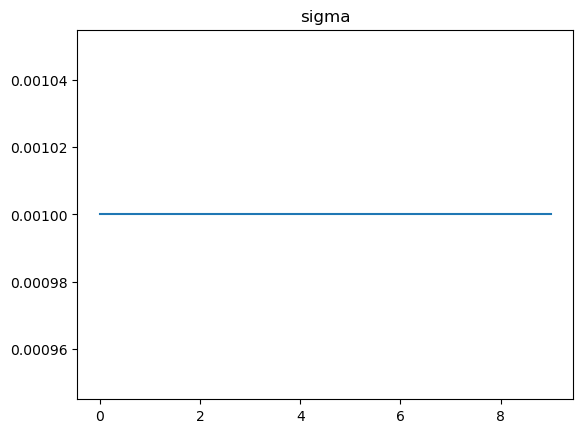

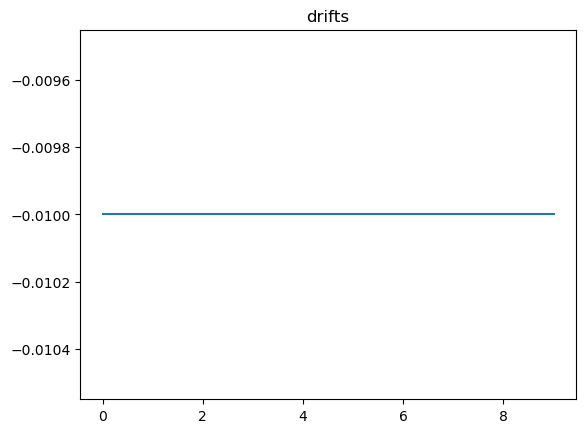

In [58]:
import torch
from tqdm import tqdm
from collections import deque

epochs=2000#0#10000000#-00
lr=100#100.0
annealing=True

n_data=10000
initial_drift=-0.01
initial_sigma=0.001

print(f"original drift: {drift}, sigma: {sigma}")
print(f"init drift: {initial_drift}, sigma: {initial_sigma}")
sample_size=int(n_data/10)
buffer_size=sample_size#now actual sample size will be hard coded as one tenth of the buffer

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

#optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)

#buffer = deque([], buffer_size)

for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()
    
    for z,t in buffer:#better use array to avoid this? its really ugly...
        if z>0.5:
            y[0,t-1]+=1
        else:
            y[1,t-1]+=1

    for _ in range(int(sample_size/10)):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recycle without getting problems for the graph
        if z>0.5:
            y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
        buffer.append((z.detach()[0], t))
    
    #y=torch.cumsum(y, 1)
    
    #should I detach?
    y=y/sample_size#torch.sum(y)


    #y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())
        
        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")
        
        

        fig, axs = plt.subplots(2)
        axs[0].bar(range(max_steps), y[0].detach(), alpha=0.5, label="model")
        axs[1].bar(range(max_steps), y[1].detach(), alpha=0.5, label="model")
        axs[0].bar(range(max_steps), corrects_old, alpha=0.5, label="original")
        axs[1].bar(range(max_steps), wrongs_old, alpha=0.5, label="original")
        plt.legend()
        plt.show()

        '''
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()'''
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.8
            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

In [64]:
sigmas[5]*10000

tensor(10.)

original drift: 0.001, sigma: 0.2


 10%|███████▋                                                                     | 399/4000 [57:13<8:40:30,  8.67s/it]

loss: 6.643094366154401e-06
sigma: 0.2999665439128876
drift: 0.004432711284607649


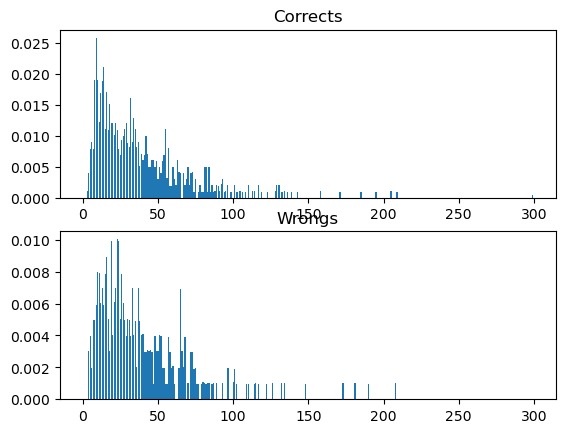

 20%|██████████████▉                                                            | 799/4000 [1:36:28<2:56:23,  3.31s/it]

loss: 7.219097824417986e-06
sigma: 0.29994744062423706
drift: 0.005276816431432962


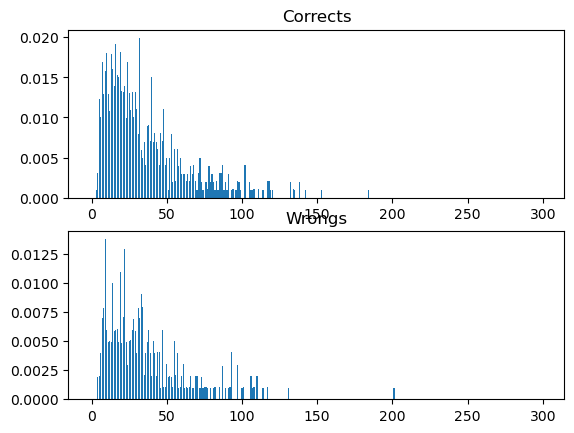

 30%|██████████████████████▏                                                   | 1199/4000 [1:58:00<1:19:21,  1.70s/it]

loss: 7.702514267293736e-06
sigma: 0.2999301850795746
drift: 0.005792326293885708


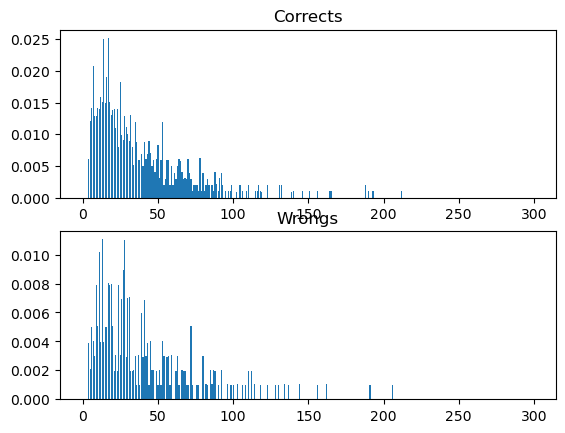

 35%|██████████████████████████                                                | 1408/4000 [2:23:08<6:12:16,  8.62s/it]

In [ ]:
import torch
from tqdm import tqdm

epochs=4000#10000000#-00
lr=0.5#100.0
annealing=False

n_data=10000
initial_drift=-0.001
initial_sigma=0.3

print(f"original drift: {drift}, sigma: {sigma}")
sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()

    for _ in range(sample_size):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recicle without getting problems for the graph
        if z>0.5:
            y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
    
    #y=torch.cumsum(y, 1)
    
    #should I detach?
    y=y/torch.sum(y)
    

    #y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())
        
        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")
        
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7
            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

In [ ]:
8.8*590

In [26]:
y.size()

torch.Size([2, 300])

In [8]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.4684]], requires_grad=True),
 Parameter containing:
 tensor([0.1934], requires_grad=True)]

In [37]:
z=torch.tensor([-0.0757])
z=(z-(z.detach())-1)*-1
print(z)
y[1,1]+=z[0]

tensor([1.])


## gridsearch

[[ 26.   1.]
 [ 54.   1.]
 [ 80.   1.]
 ...
 [ 44.  -1.]
 [ 49.   1.]
 [103.   1.]]
wrongs: 3519
      response     rt
0          1.0   26.0
1          1.0   54.0
2          1.0   80.0
3          1.0  203.0
4         -1.0   78.0
...        ...    ...
9995       1.0   64.0
9996      -1.0  101.0
9997      -1.0   44.0
9998       1.0   49.0
9999       1.0  103.0

[10000 rows x 2 columns]


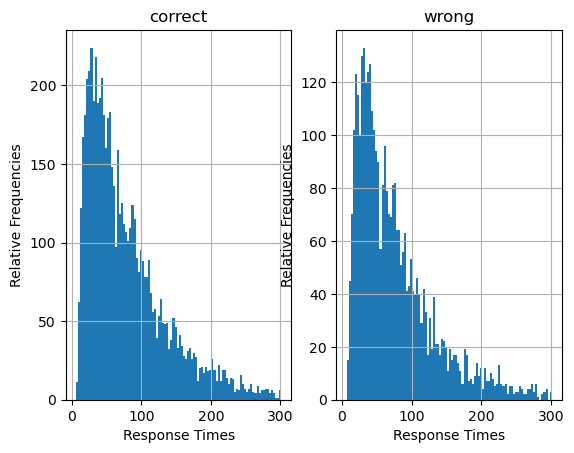

9549


In [5]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.ndimage import gaussian_filter1d

os.environ["KMP_DUPLICATE_LIB_OK"] = "True"

z0=0.5
sigma=0.2
drift=0.002
max_steps=300
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]

print("wrongs:",(df["response"]==-1).sum())

ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

'''for i in range(max_steps):
    corrects[i]=corrects[:i+1].sum()
    wrongs[i]=wrongs[:i+1].sum()'''

#corrects=np.cumsum(corrects)
#wrongs=np.cumsum(wrongs)



corrects=gaussian_filter1d(corrects, 6, mode="constant")
wrongs=gaussian_filter1d(wrongs, 6, mode="constant")

cum=np.sum(corrects+wrongs)

corrects_old=corrects/cum
wrongs_old=wrongs/cum
cum_old=cum/cum

print(cum)
target[:max_steps]=torch.from_numpy(corrects)#/cum)
target[max_steps:]=torch.from_numpy(wrongs)#/cum)


In [14]:
0.000000001

1e-09

In [ ]:
import torch
from tqdm import tqdm
from collections import deque

epochs=6000#0#10000000#-00
lr=100#100.0
annealing=False

n_data=10000
initial_drift=-0.01
initial_sigma=0.001

sample_size=int(n_data/10)
buffer_size=sample_size#now actual sample size will be hard coded as one tenth of the buffer

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)



loss_function = torch.nn.MSELoss()#CrossEntropyLoss()



for lr in (1e-8, 1e-9):
    for initial_sigma, initial_drift in ((0.001, -0.01),):
        print("lr",lr)
        
        losses=[]
        sigmas=[]
        drifts=[]
        
        model=DDMTorch()
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0)

        
        model.layer.weight.data.fill_(initial_sigma)
        model.layer.bias.data.fill_(initial_drift)
        buffer = deque([], buffer_size)
        
        print(f"original drift: {drift}, sigma: {sigma}")
        print(f"init drift: {initial_drift}, sigma: {initial_sigma}")

        for i in tqdm(range(epochs)):
            y=torch.zeros((2,max_steps))
            optimizer.zero_grad()

            for z,t in buffer:#better use array to avoid this? its really ugly...
                if z>0.5:
                    y[0,t-1]+=1
                else:
                    y[1,t-1]+=1

            for _ in range(int(sample_size/10)):
                z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recycle without getting problems for the graph
                if z>0.5:
                    y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
                else:
                    y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
                buffer.append((z.detach()[0], t))

            #y=torch.cumsum(y, 1)

            #should I detach?
            y=y*(n_data/sample_size)#/sample_size#torch.sum(y)


            #y=y/sample_size#y.sum()
            loss=loss_function(torch.concat((y[0],y[1])), target)
            losses.append(loss.item())

            sigmas.append(model.layer.weight.data[0,0].detach().clone())
            drifts.append(model.layer.bias.data[0].detach().clone())

            loss.backward()
            optimizer.step()

            """if not (i+1)%int(epochs/10):
                #print("loss:", np.mean(losses[-1]))


                #print(f"sigma: {sigmas[-1]}")
                #print(f"drift: {drifts[-1]}")



                '''fig, axs = plt.subplots(2)
                axs[0].bar(range(max_steps), y[0].detach(), alpha=0.5, label="model")
                axs[1].bar(range(max_steps), y[1].detach(), alpha=0.5, label="model")
                axs[0].bar(range(max_steps), corrects_old, alpha=0.5, label="original")
                axs[1].bar(range(max_steps), wrongs_old, alpha=0.5, label="original")
                plt.legend()
                plt.show()'''

                '''
                fig, axs = plt.subplots(2)
                axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
                axs[0].title.set_text("Corrects")
                axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
                axs[1].title.set_text("Wrongs")
                plt.show()'''

                if annealing:
                    for group in optimizer.param_groups:
                        group['lr'] *= 0.8"""

        plt.plot(range(len(losses)), losses)
        plt.title("loss")
        plt.show()
        plt.plot(range(len(sigmas)), sigmas)
        plt.title("sigma")
        plt.show()
        plt.plot(range(len(drifts)), drifts)
        plt.title("drifts")
        plt.show()
        
        name = f"big_mse_{lr}_{initial_sigma}_{initial_drift}"
        torch.save(model.state_dict(), name+".pt")
        np.save("losses_"+name, np.array(losses))
        np.save("drifts_"+name, np.array(drifts))
        np.save("sigmas_"+name, np.array(sigmas))
               

lr 1e-08
original drift: 0.002, sigma: 0.2
init drift: -0.01, sigma: 0.001


 96%|████████████████████████████████████████████████████████████████████████▊   | 5746/6000 [4:48:44<07:36,  1.80s/it]

In [ ]:
import torch
from tqdm import tqdm
from collections import deque

epochs=6000#0#10000000#-00
lr=100#100.0
annealing=False

n_data=10000
initial_drift=-0.01
initial_sigma=0.001

sample_size=int(n_data/10)
buffer_size=sample_size#now actual sample size will be hard coded as one tenth of the buffer

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)



loss_function = torch.nn.MSELoss()#CrossEntropyLoss()



for lr in (1e-8, 1e-9):
    for initial_sigma, initial_drift in ((0.001, -0.01),):
        print("lr",lr)
        
        losses=[]
        sigmas=[]
        drifts=[]
        
        model=DDMTorch()
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0)

        
        model.layer.weight.data.fill_(initial_sigma)
        model.layer.bias.data.fill_(initial_drift)
        buffer = deque([], buffer_size)
        
        print(f"original drift: {drift}, sigma: {sigma}")
        print(f"init drift: {initial_drift}, sigma: {initial_sigma}")

        for i in tqdm(range(epochs)):
            y=torch.zeros((2,max_steps))
            optimizer.zero_grad()

            for z,t in buffer:#better use array to avoid this? its really ugly...
                if z>0.5:
                    y[0,t-1]+=1
                else:
                    y[1,t-1]+=1

            for _ in range(int(sample_size/10)):
                z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recycle without getting problems for the graph
                if z>0.5:
                    y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
                else:
                    y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
                buffer.append((z.detach()[0], t))

            #y=torch.cumsum(y, 1)

            #should I detach?
            y=y*(n_data/sample_size)#/sample_size#torch.sum(y)


            #y=y/sample_size#y.sum()
            loss=loss_function(torch.concat((y[0],y[1])), target)
            losses.append(loss.item())

            sigmas.append(model.layer.weight.data[0,0].detach().clone())
            drifts.append(model.layer.bias.data[0].detach().clone())

            loss.backward()
            optimizer.step()

            """if not (i+1)%int(epochs/10):
                #print("loss:", np.mean(losses[-1]))


                #print(f"sigma: {sigmas[-1]}")
                #print(f"drift: {drifts[-1]}")



                '''fig, axs = plt.subplots(2)
                axs[0].bar(range(max_steps), y[0].detach(), alpha=0.5, label="model")
                axs[1].bar(range(max_steps), y[1].detach(), alpha=0.5, label="model")
                axs[0].bar(range(max_steps), corrects_old, alpha=0.5, label="original")
                axs[1].bar(range(max_steps), wrongs_old, alpha=0.5, label="original")
                plt.legend()
                plt.show()'''

                '''
                fig, axs = plt.subplots(2)
                axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
                axs[0].title.set_text("Corrects")
                axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
                axs[1].title.set_text("Wrongs")
                plt.show()'''

                if annealing:
                    for group in optimizer.param_groups:
                        group['lr'] *= 0.8"""

        plt.plot(range(len(losses)), losses)
        plt.title("loss")
        plt.show()
        plt.plot(range(len(sigmas)), sigmas)
        plt.title("sigma")
        plt.show()
        plt.plot(range(len(drifts)), drifts)
        plt.title("drifts")
        plt.show()
        
        name = f"big_mse_{lr}_{initial_sigma}_{initial_drift}"
        torch.save(model.state_dict(), name+".pt")
        np.save("losses_"+name, np.array(losses))
        np.save("drifts_"+name, np.array(drifts))
        np.save("sigmas_"+name, np.array(sigmas))
               

original drift: 0.002, sigma: 0.2
init drift: -0.01, sigma: 0.001


100%|████████████████████████████████████████████████████████████████████████████| 6000/6000 [2:37:37<00:00,  1.58s/it]


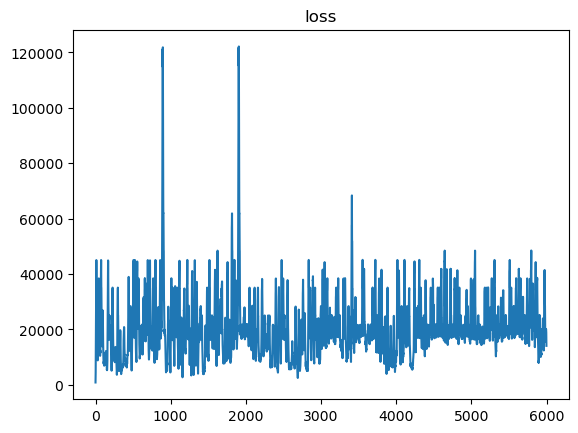

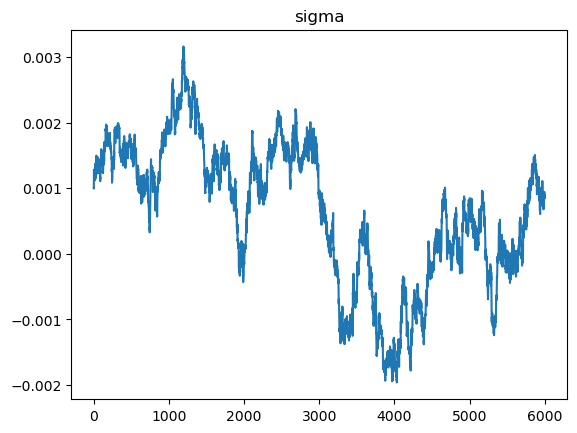

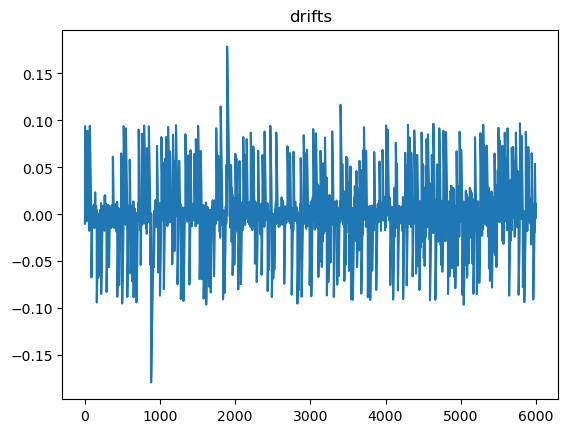

original drift: 0.002, sigma: 0.2
init drift: -0.01, sigma: 0.001


100%|████████████████████████████████████████████████████████████████████████████| 6000/6000 [5:41:35<00:00,  3.42s/it]


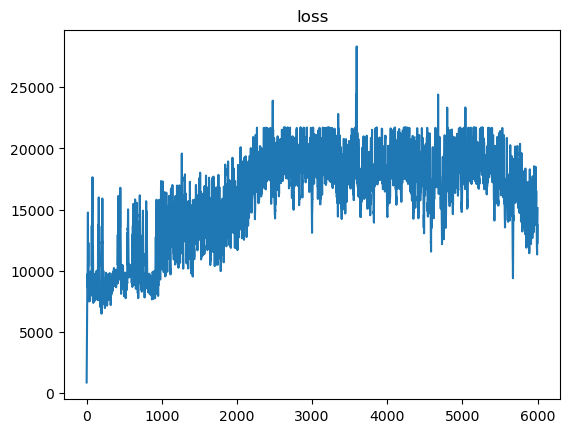

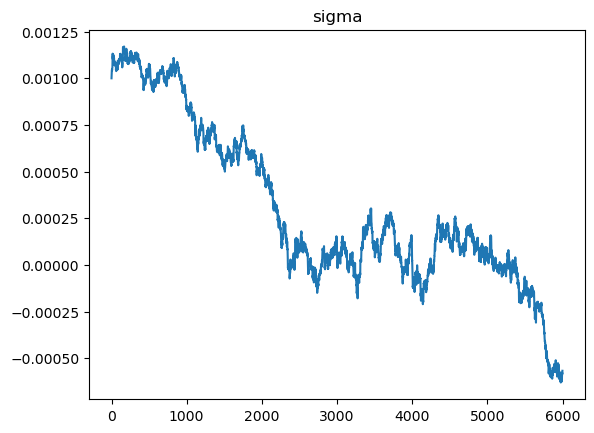

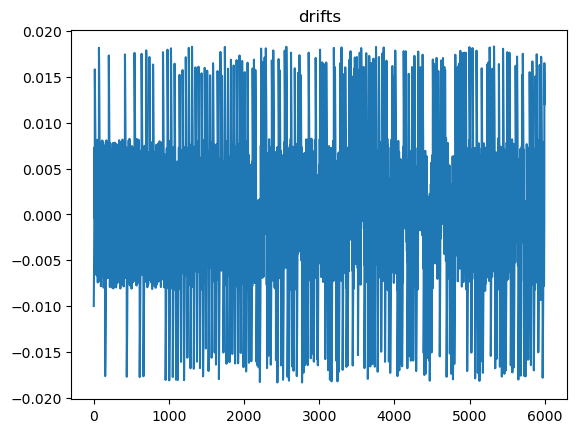

In [8]:
import torch
from tqdm import tqdm
from collections import deque

epochs=6000#0#10000000#-00
lr=100#100.0
annealing=False

n_data=10000
initial_drift=-0.01
initial_sigma=0.001

sample_size=int(n_data/10)
buffer_size=sample_size#now actual sample size will be hard coded as one tenth of the buffer

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)



loss_function = torch.nn.MSELoss()#CrossEntropyLoss()



for lr in (0.0000001, 0.00000001):
    for initial_sigma, initial_drift in ((0.001, -0.01),):
        print("lr",lr)
        
        losses=[]
        sigmas=[]
        drifts=[]
        
        model=DDMTorch()
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0)

        
        model.layer.weight.data.fill_(initial_sigma)
        model.layer.bias.data.fill_(initial_drift)
        buffer = deque([], buffer_size)
        
        print(f"original drift: {drift}, sigma: {sigma}")
        print(f"init drift: {initial_drift}, sigma: {initial_sigma}")

        for i in tqdm(range(epochs)):
            y=torch.zeros((2,max_steps))
            optimizer.zero_grad()

            for z,t in buffer:#better use array to avoid this? its really ugly...
                if z>0.5:
                    y[0,t-1]+=1
                else:
                    y[1,t-1]+=1

            for _ in range(int(sample_size/10)):
                z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recycle without getting problems for the graph
                if z>0.5:
                    y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
                else:
                    y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
                buffer.append((z.detach()[0], t))

            #y=torch.cumsum(y, 1)

            #should I detach?
            y=y*(n_data/sample_size)#/sample_size#torch.sum(y)


            #y=y/sample_size#y.sum()
            loss=loss_function(torch.concat((y[0],y[1])), target)
            losses.append(loss.item())

            sigmas.append(model.layer.weight.data[0,0].detach().clone())
            drifts.append(model.layer.bias.data[0].detach().clone())

            loss.backward()
            optimizer.step()

            """if not (i+1)%int(epochs/10):
                #print("loss:", np.mean(losses[-1]))


                #print(f"sigma: {sigmas[-1]}")
                #print(f"drift: {drifts[-1]}")



                '''fig, axs = plt.subplots(2)
                axs[0].bar(range(max_steps), y[0].detach(), alpha=0.5, label="model")
                axs[1].bar(range(max_steps), y[1].detach(), alpha=0.5, label="model")
                axs[0].bar(range(max_steps), corrects_old, alpha=0.5, label="original")
                axs[1].bar(range(max_steps), wrongs_old, alpha=0.5, label="original")
                plt.legend()
                plt.show()'''

                '''
                fig, axs = plt.subplots(2)
                axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
                axs[0].title.set_text("Corrects")
                axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
                axs[1].title.set_text("Wrongs")
                plt.show()'''

                if annealing:
                    for group in optimizer.param_groups:
                        group['lr'] *= 0.8"""

        plt.plot(range(len(losses)), losses)
        plt.title("loss")
        plt.show()
        plt.plot(range(len(sigmas)), sigmas)
        plt.title("sigma")
        plt.show()
        plt.plot(range(len(drifts)), drifts)
        plt.title("drifts")
        plt.show()
        
        name = f"big_mse_{lr}_{initial_sigma}_{initial_drift}"
        torch.save(model.state_dict(), name+".pt")
        np.save("losses_"+name, np.array(losses))
        np.save("drifts_"+name, np.array(drifts))
        np.save("sigmas_"+name, np.array(sigmas))
               

In [64]:
sigmas[5]*10000

tensor(10.)

original drift: 0.001, sigma: 0.2


 10%|███████▋                                                                     | 399/4000 [57:13<8:40:30,  8.67s/it]

loss: 6.643094366154401e-06
sigma: 0.2999665439128876
drift: 0.004432711284607649


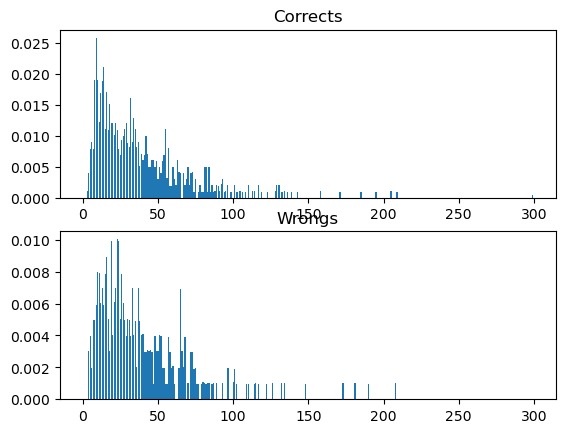

 20%|██████████████▉                                                            | 799/4000 [1:36:28<2:56:23,  3.31s/it]

loss: 7.219097824417986e-06
sigma: 0.29994744062423706
drift: 0.005276816431432962


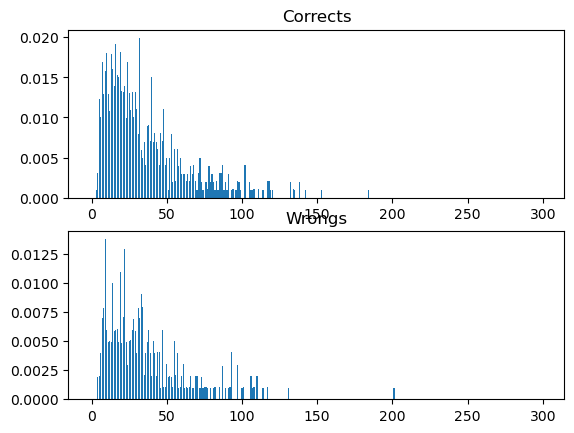

 30%|██████████████████████▏                                                   | 1199/4000 [1:58:00<1:19:21,  1.70s/it]

loss: 7.702514267293736e-06
sigma: 0.2999301850795746
drift: 0.005792326293885708


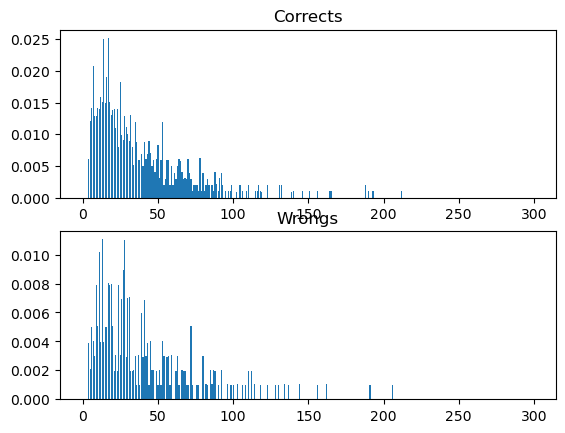

 35%|██████████████████████████                                                | 1408/4000 [2:23:08<6:12:16,  8.62s/it]

In [ ]:
import torch
from tqdm import tqdm

epochs=4000#10000000#-00
lr=0.5#100.0
annealing=False

n_data=10000
initial_drift=-0.001
initial_sigma=0.3

print(f"original drift: {drift}, sigma: {sigma}")
sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()

    for _ in range(sample_size):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recicle without getting problems for the graph
        if z>0.5:
            y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
    
    #y=torch.cumsum(y, 1)
    
    #should I detach?
    y=y/torch.sum(y)
    

    #y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())
        
        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")
        
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7
            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

In [ ]:
8.8*590

In [26]:
y.size()

torch.Size([2, 300])

In [8]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.4684]], requires_grad=True),
 Parameter containing:
 tensor([0.1934], requires_grad=True)]

In [37]:
z=torch.tensor([-0.0757])
z=(z-(z.detach())-1)*-1
print(z)
y[1,1]+=z[0]

tensor([1.])


## MSE (cumsum) unnormalized
- still look above

- maybe it shoud be cumsum, so that ts get more pulled towards being late (otherwise being late is part of the loss but not taken into account for differention

In [ ]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt

z0=0.5
sigma=0.2
drift=0.001
max_steps=300
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]

print("wrongs:",(df["response"]==-1).sum())

ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

'''for i in range(max_steps):
    corrects[i]=corrects[:i+1].sum()
    wrongs[i]=wrongs[:i+1].sum()'''

#corrects=np.cumsum(corrects)
#wrongs=np.cumsum(wrongs)

corrects=gaussian_filter1d(corrects, 6, mode="constant")
wrongs=gaussian_filter1d(wrongs, 6, mode="constant")

cum=1#np.sum(corrects+wrongs)

corrects_old=corrects
wrongs_old=wrongs
cum_old=cum

print(cum)
target[:max_steps]=torch.from_numpy(corrects/cum)
target[max_steps:]=torch.from_numpy(wrongs/cum)


In [ ]:
import torch
from tqdm import tqdm

epochs=400#10000000#-00
lr=0.1#100.0
annealing=True

n_data=10000
initial_drift=0.0
initial_sigma=0.3

print(f"original drift: {drift}, sigma: {sigma}")
sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()

    for _ in range(sample_size):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recicle without getting problems for the graph
        if z>0.5:
            y[0,t-1]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t-1]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
    
    #y=torch.cumsum(y, 1)
    
    #should I detach?
    y=y/(sample_size/n_data)#torch.sum(y)
    

    #y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())
        
        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")
        
        cum=sample_size

        fig, axs = plt.subplots(2)
        axs[0].bar(range(max_steps), y[0]/cum, alpha=0.5, label="model")
        axs[1].bar(range(max_steps), y[1]/cum, alpha=0.5, label="model")

        axs[0].bar(range(max_steps), corrects_old/cum_old, alpha=0.5, label="original")
        axs[1].bar(range(max_steps), wrongs_old/cum_old, alpha=0.5, label="original")
        plt.legend()
        plt.show()
        
        '''
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()'''
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7
            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

In [23]:
print(model.layer.weight.data)
print(model.layer.bias.data)

tensor([[0.3000]])
tensor([0.0205])


In [8]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.4684]], requires_grad=True),
 Parameter containing:
 tensor([0.1934], requires_grad=True)]

In [37]:
z=torch.tensor([-0.0757])
z=(z-(z.detach())-1)*-1
print(z)
y[1,1]+=z[0]

tensor([1.])


## MSE(z, p(z|t)) for all t
p(z|t) unknown, but could be approximated by argmax_z(p(z>=1)) which will be assumed to be directly in the middle of the two

In [ ]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt

z0=0.5
sigma=0.2
drift=0.001
max_steps=300
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]

print("wrongs:",(df["response"]==-1).sum())

ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

'''for i in range(max_steps):
    corrects[i]=corrects[:i+1].sum()
    wrongs[i]=wrongs[:i+1].sum()'''

#corrects=np.cumsum(corrects)
#wrongs=np.cumsum(wrongs)

corrects=gaussian_filter1d(corrects, 6, mode="constant")
wrongs=gaussian_filter1d(wrongs, 6, mode="constant")

corrects_old=corrects
wrongs_old=wrongs
cum_old=cum

print(cum)
target=torch.from_numpy(corrects/(corrects+wrongs)


In [28]:
import torch
from tqdm import tqdm

epochs=400#10000000#-00
lr=0.1#100.0
annealing=True

n_data=10000
initial_drift=0.0
initial_sigma=0.3

print(f"original drift: {drift}, sigma: {sigma}")
sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z, t):
        t+=1
        inp = torch.rand(1)-0.5
        output=self.layer(inp)
        z=output+z
        
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)


loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    y=torch.zeros((2,max_steps))
    optimizer.zero_grad()

    for _ in range(sample_size):
        z, t = model(torch.Tensor([0.5]), 0)#dunno if we can recicle without getting problems for the graph
        if z>0.5:
            y[0,t]+=z[0]#(z-(z.detach()-1))[0]#lets see if this is more of a bias than the mean-trickif z>0.5:
        else:
            y[1,t]+=(z[0]-1)*-1#((z-(z.detach())-1)*-1)[0]
    
    #y=torch.cumsum(y, 1)
    
    #should I detach?
    y=y/(sample_size/n_data)#torch.sum(y)
    

    #y=y/sample_size#y.sum()
    loss=loss_function(torch.concat((y[0],y[1])), target)
    losses.append(loss.item())
    
    loss.backward()
    optimizer.step()
    
    if not (i+1)%int(epochs/10):
        print("loss:", np.mean(losses[-1]))
        
        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())
        
        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")
        
        cum=sample_size

        fig, axs = plt.subplots(2)
        axs[0].bar(range(max_steps), y[0]/cum, alpha=0.5, label="model")
        axs[1].bar(range(max_steps), y[1]/cum, alpha=0.5, label="model")

        axs[0].bar(range(max_steps), corrects_old/cum_old, alpha=0.5, label="original")
        axs[1].bar(range(max_steps), wrongs_old/cum_old, alpha=0.5, label="original")
        plt.legend()
        plt.show()
        
        '''
        fig, axs = plt.subplots(2)
        axs[0].bar(np.arange(max_steps),y[0].detach().numpy())
        axs[0].title.set_text("Corrects")
        axs[1].bar(np.arange(max_steps),y[1].detach().numpy())
        axs[1].title.set_text("Wrongs")
        plt.show()'''
        
        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7
            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

original drift: 0.001, sigma: 0.2


  2%|██                                                                               | 10/400 [00:08<05:42,  1.14it/s]


IndexError: index 300 is out of bounds for dimension 1 with size 300

In [23]:
print(model.layer.weight.data)
print(model.layer.bias.data)

tensor([[0.3000]])
tensor([0.0205])


In [8]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.4684]], requires_grad=True),
 Parameter containing:
 tensor([0.1934], requires_grad=True)]

In [37]:
z=torch.tensor([-0.0757])
z=(z-(z.detach())-1)*-1
print(z)
y[1,1]+=z[0]

tensor([1.])


## checkout torch overwrite

In [ ]:
from overwrite_torch import new_sgd
import torch

torch.optim.sgd._single_tensor_sgd = new_sgd
net=torch.nn.linear(2,1)
loss_function = torch.nn.MSELoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.5)

for _ in range(10):
    x = torch.random(2)
    y=net(x)
    loss=loss_function(y,1)
    loss.backward()
    optim.step()

## check out CE values

In [11]:
df["plausible"]=0
df

,response,rt,plausible
0,-1.0,33.0,0
1,1.0,96.0,0
2,-1.0,50.0,0
3,1.0,297.0,0
4,1.0,87.0,0
...,...,...,...
9995,1.0,167.0,0
9996,1.0,39.0,0
9997,1.0,27.0,0
9998,-1.0,102.0,0


[[14.  1.]
 [54.  1.]
 [88.  1.]
 ...
 [53.  1.]
 [19.  1.]
 [68.  1.]]
wrongs: 396
      response    rt
0          1.0  14.0
1          1.0  54.0
2          1.0  88.0
3          1.0  83.0
4          1.0  19.0
...        ...   ...
9995       1.0  96.0
9996       1.0  97.0
9997       1.0  53.0
9998       1.0  19.0
9999       1.0  68.0

[10000 rows x 2 columns]


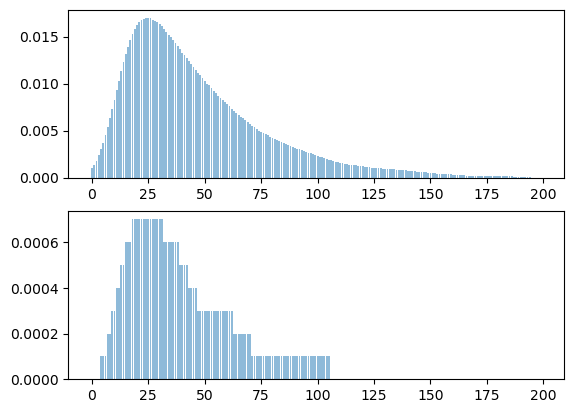

10000


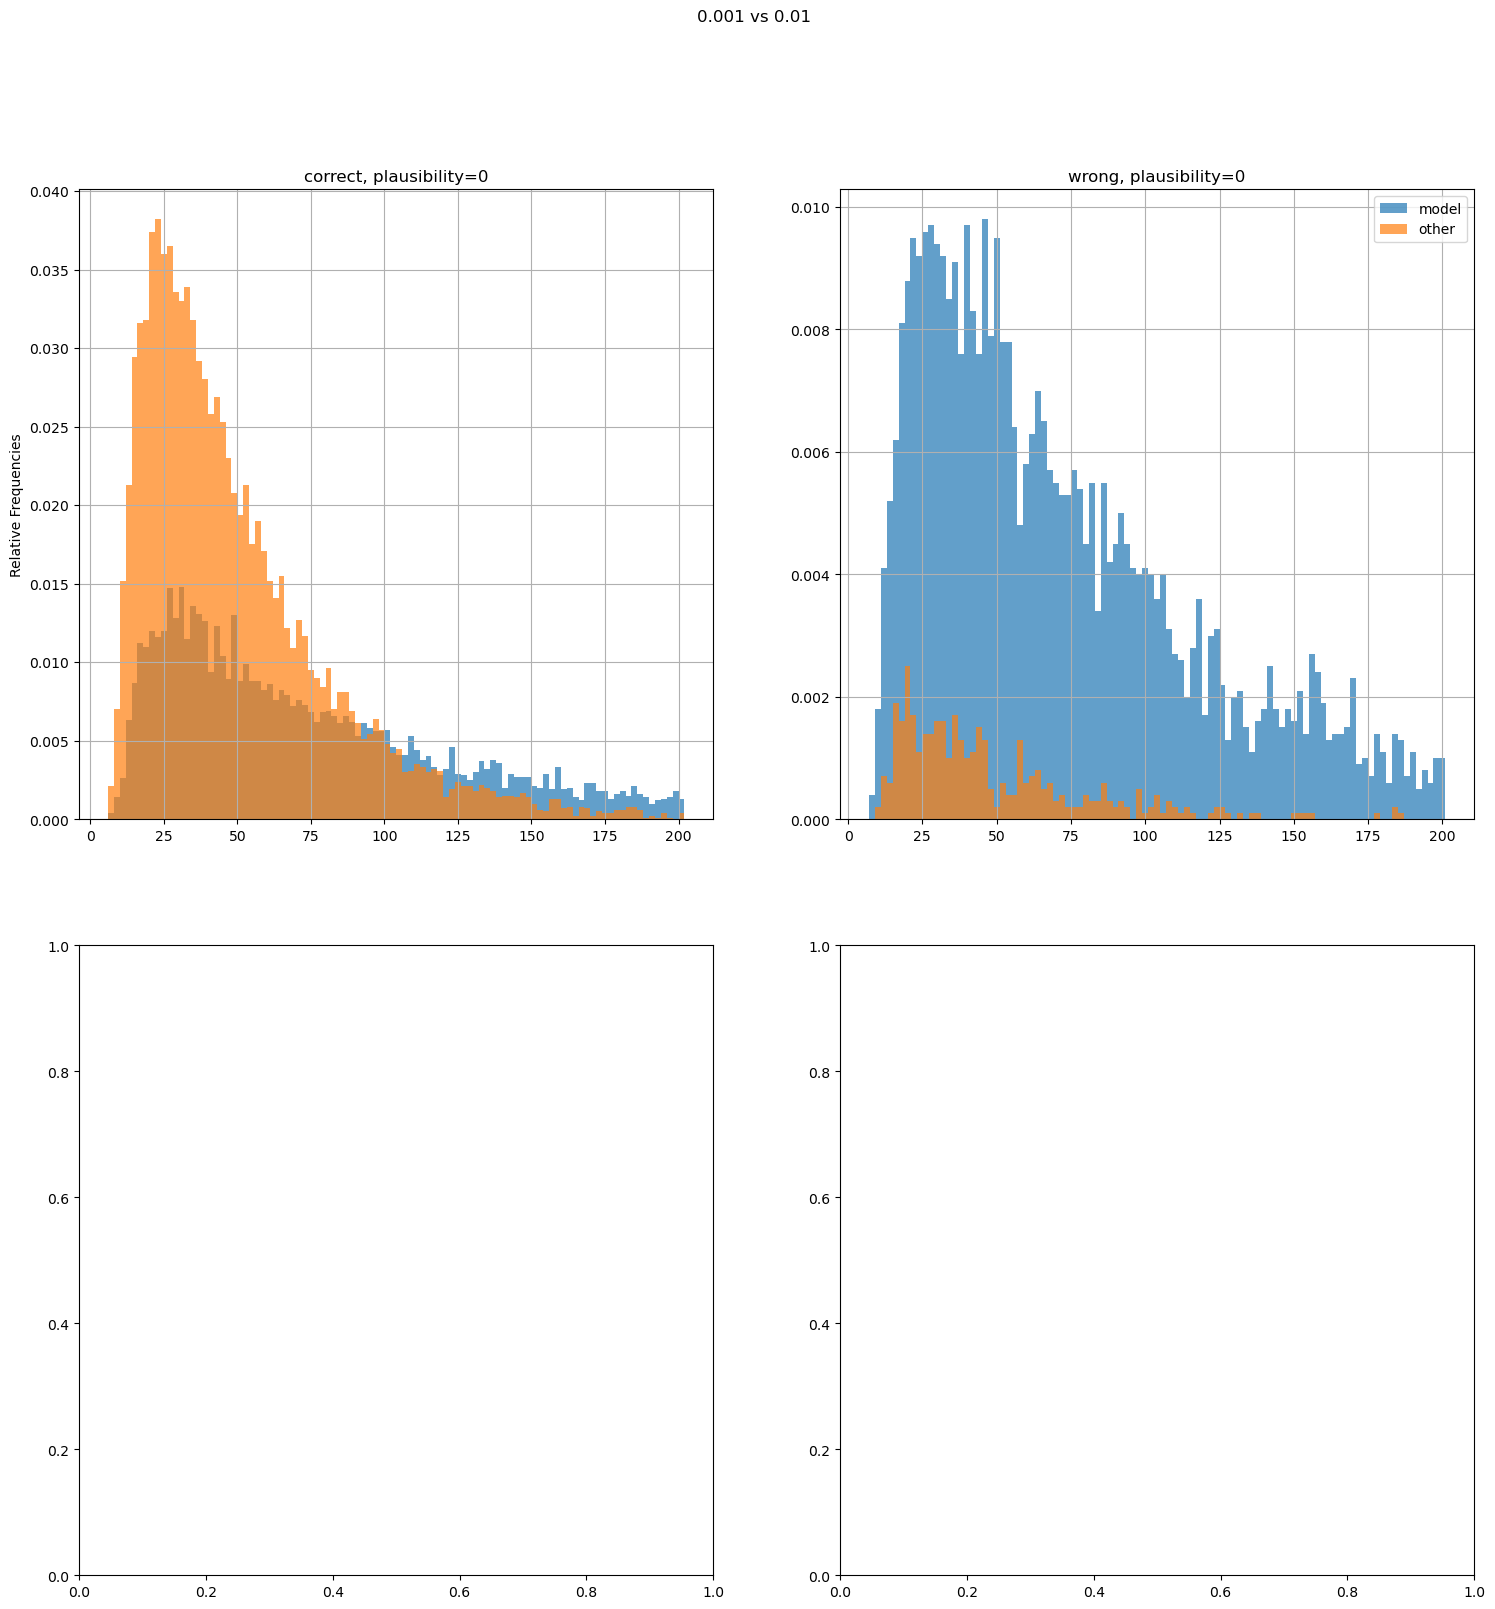

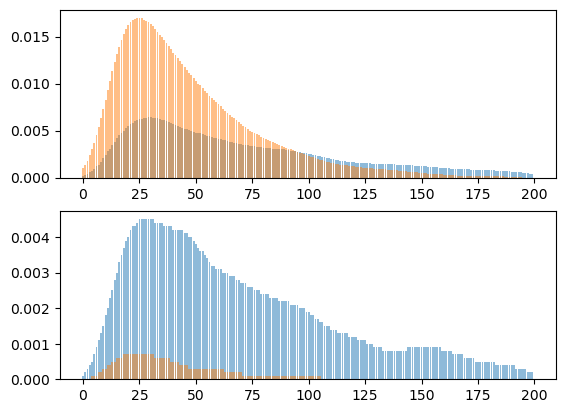

for drift = 0.001 ce is: 1.1199701475561596e-05


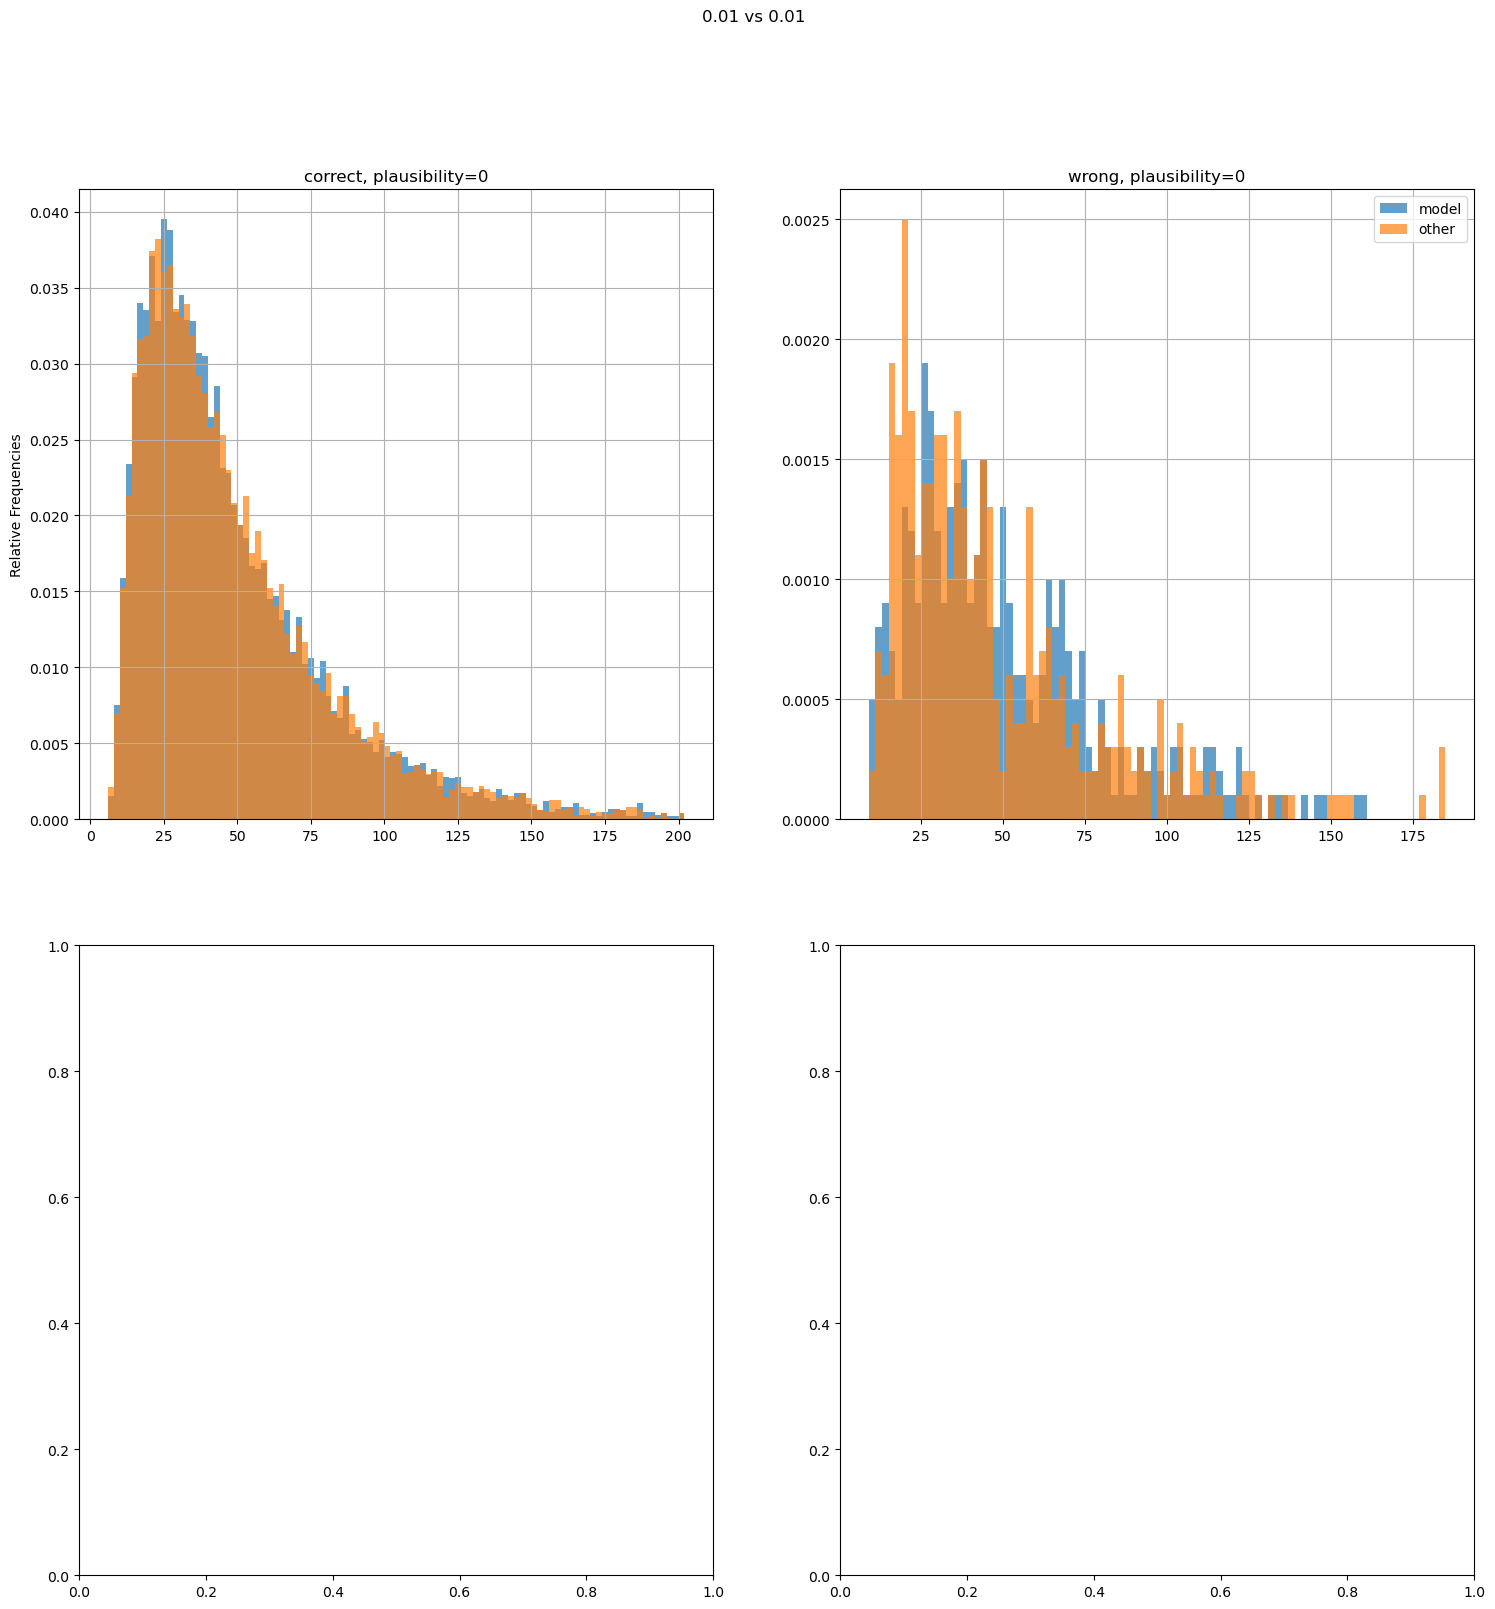

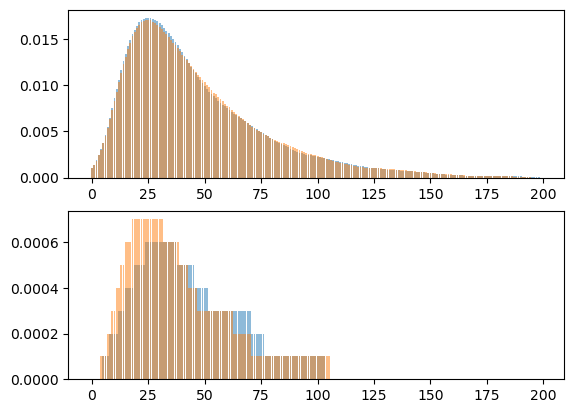

for drift = 0.01 ce is: 2.0100001663081457e-08


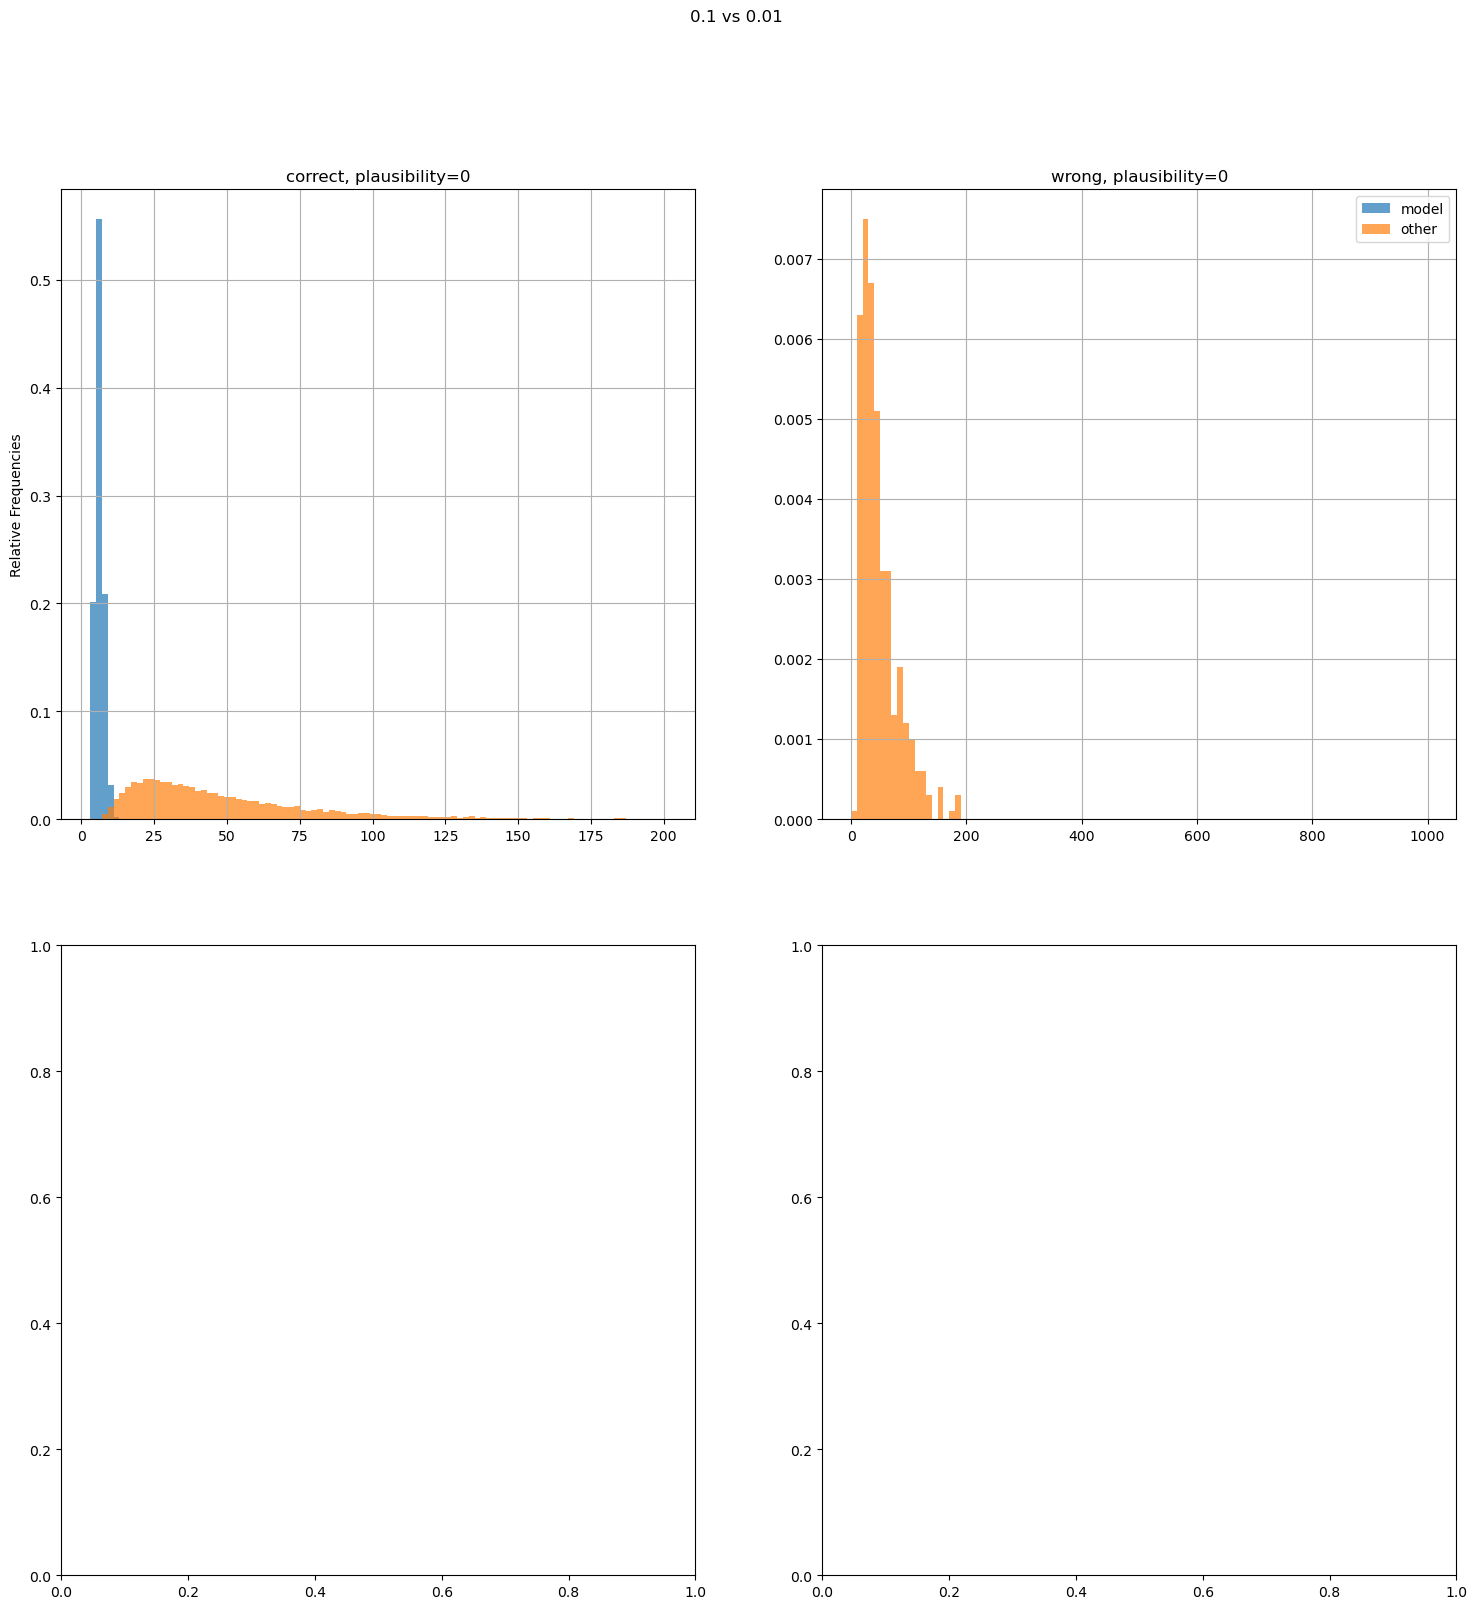

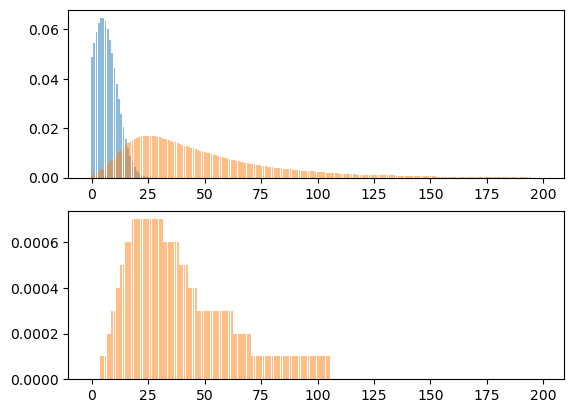

for drift = 0.1 ce is: 0.00010370377276558429


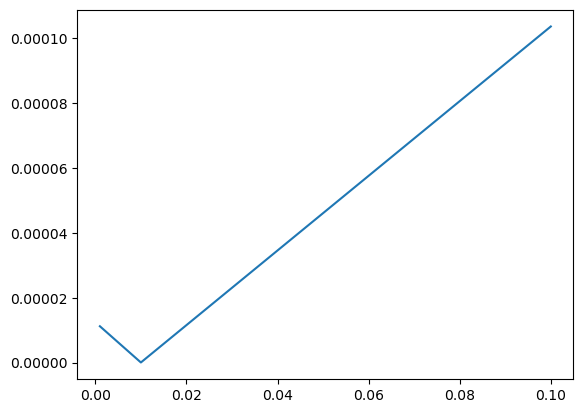

In [18]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "True"

from scipy.ndimage import gaussian_filter1d


gaussian_filter1d([1.0, 2.0, 3.0, 4.0, 5.0], 6, mode="constant")


z0=0.5
sigma=0.2
drift=0.01
max_steps=200
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]

print("wrongs:",(df["response"]==-1).sum())

ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
#ddm.plot_histogram(conditions=[])

target_df=df
target_df["plausible"]=0

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

'''for i in range(max_steps):
    corrects[i]=corrects[:i+1].sum()
    wrongs[i]=wrongs[:i+1].sum()'''

#corrects=np.cumsum(corrects)
#wrongs=np.cumsum(wrongs)

cum=n_data#1#np.sum(corrects+wrongs)

corrects=gaussian_filter1d(corrects, 6, mode="constant")
wrongs=gaussian_filter1d(wrongs, 6, mode="constant")

corrects_old=corrects
wrongs_old=wrongs
cum_old=cum

fig, axs = plt.subplots(2)
axs[0].bar(range(max_steps), corrects/cum, alpha=0.5)
axs[1].bar(range(max_steps), wrongs/cum, alpha=0.5)
plt.show()

print(cum)
target[:max_steps]=torch.from_numpy(corrects/cum)
target[max_steps:]=torch.from_numpy(wrongs/cum)
losses=[]

conditions=(0.001, 0.01, 0.1)
loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
drift_old=drift

for drift in conditions:

    z0=0.5
    sigma=0.2
    epochs=10000000#-00
    n_data=10000

    sample_size=n_data

    ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

    dataset=generate_data_t(ddm_net, max_steps, n=n_data)
    df=pd.DataFrame()
    df["response"]=dataset[:,1]
    df["rt"]=dataset[:,0]
    df["plausible"]=0

    #print("wrongs:",(df["response"]==-1).sum())

    ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
    ddm.log=df
    ddm.compare(target_df, conditions=[0], title=f"{drift} vs {drift_old}")

    y=torch.zeros(2*max_steps)
    #print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
    corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
    wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

    '''for i in range(max_steps):
        corrects[i]=corrects[:i+1].sum()
        wrongs[i]=wrongs[:i+1].sum()'''

    #corrects=np.cumsum(corrects)
    #wrongs=np.cumsum(wrongs)

    cum=sample_size#1#np.sum(corrects+wrongs)
    
    corrects=gaussian_filter1d(corrects, 6, mode="constant")
    wrongs=gaussian_filter1d(wrongs, 6, mode="constant")

    fig, axs = plt.subplots(2)
    axs[0].bar(range(max_steps), corrects/cum, alpha=0.5)
    axs[1].bar(range(max_steps), wrongs/cum, alpha=0.5)
    
    axs[0].bar(range(max_steps), corrects_old/cum_old, alpha=0.5)
    axs[1].bar(range(max_steps), wrongs_old/cum_old, alpha=0.5)
    
    
    plt.show()
    
    y[:max_steps]=torch.from_numpy(corrects/cum)
    y[max_steps:]=torch.from_numpy(wrongs/cum)
    
    
    
    loss=loss_function(y,target)
    print(f"for drift = {drift} ce is: {loss}")
    losses.append(loss)
    
plt.plot(conditions, losses)

## end